# Advanced Algorithms: Linear and Integer Programming

> **Prerequisite:** [`advanced_algorithms/02` NP-completeness and reductions](02_np_completeness_and_reductions.ipynb) (why integer programming is hard) and [`dsa/09` Dynamic programming](../dsa/09_dynamic_programming.ipynb) (the 0/1 knapsack DP we compare against).
>
> **Who is this for:** you know Python and a little algebra and you want the optimisation workhorse behind scheduling, logistics, ad allocation and many ML formulations. It is also for students revising the "Linear Programming" chapter of an algorithms or operations-research course.
>
> **What you will learn:**
> - How to turn a word problem into a **linear program (LP)**: decision variables, objective, constraints (production, diet and transport problems)
> - The **geometry** of an LP: the feasible region is a polygon (polytope) and an optimum sits at a **vertex**
> - A **tableau simplex method** written from scratch (two-phase, with **Bland's rule**), checked against `scipy.optimize.linprog(method="highs")` on hundreds of random LPs; **cycling** and the **Klee–Minty** worst case
> - **LP duality**: build the dual, verify weak and strong duality, read **shadow prices**
> - **Integer programming (ILP/MILP)**: why rounding fails, **branch-and-bound** from scratch (knapsack, facility location), `scipy.optimize.milp`
> - **Modelling tricks**: big-M, binary indicators, absolute values, min-max
> - **Sensitivity analysis** and **infeasibility diagnosis** (finding an irreducible infeasible subset)
> - AI uses: **L1 regression** and the **L1-SVM** as LPs, GPU job scheduling and ad-budget allocation
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [NumPy](../../02_Data_Analysis/02_numpy.ipynb); solving two linear equations in two unknowns. The [optimization notebook](../../14_Mathematics/06_optimization.ipynb) (gradient methods, Lagrange multipliers) is useful background but not required.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about one to two minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows CLRS (4th ed.) ch. 29 (linear programming), Bertsimas & Tsitsiklis, *Introduction to Linear Optimization*, and Wolsey, *Integer Programming*.

## Explained simply

Linear programming is a way to find the **best plan when you have limited resources**. You write down three things: what you can choose (for example, how many of each product to make), what you want (the most profit or the lowest cost), and your limits (hours, money, space). A solver then finds the choice that respects every limit and is better than every other such choice. Think of a café deciding how many sandwiches and salads to make with a limited amount of bread and lettuce, or a delivery company deciding which van carries which parcels so that fuel costs are lowest. **Integer programming** is the same idea when some answers must be whole numbers or yes/no decisions: you cannot rent 2.4 buses or half-open a warehouse. That small change makes the problem much harder, so we use a clever "split and skip" search called branch-and-bound.

**Tiny example.** A workshop earns \$300 per desk and \$500 per chair. Machine A can make at most 4 desks a week; machine B gives chairs 12 hours (2 hours each, so at most 6 chairs); machine C has 18 hours and needs 3 hours per desk and 2 per chair. Making 6 chairs uses 12 of machine C's hours, leaving 6 hours for 2 desks. Profit: $2 \times 300 + 6 \times 500 = \$3{,}600$, and no other plan that fits the machines earns more.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Linear program (LP) | the best plan when every rule is a "straight-line" limit | delivery routes, diet planning, splitting an ad budget |
| Integer program (ILP) | the same, but with whole-number or yes/no choices | which warehouses to open, assigning training jobs to GPUs |
| Shadow price (duality) | how much one more unit of a resource is worth | "is one more GPU-hour or \$1,000 of budget worth buying?" |

### How this notebook is different from `14_Mathematics/06_optimization`
[`06_optimization`](../../14_Mathematics/06_optimization.ipynb) is about **continuous, smooth** optimisation with gradients (gradient descent, momentum, Adam). Here the objective and constraints are **linear** and the variables may have to be **integers**. Gradients do not help with "choose 3 of these 8 jobs"; instead we walk along the corners of a polytope (simplex) and split the search space (branch-and-bound).

## Table of contents
0. Setup
1. Modelling: from words to a linear program
2. The geometry of an LP: why the optimum is at a vertex
3. The simplex method from scratch
4. LP duality and shadow prices
5. Integer programming and branch-and-bound
6. Modelling tricks: big-M, indicators, absolute values, min-max
7. Sensitivity analysis and infeasibility diagnosis
8. How this connects to modern AI: L1 regression, L1-SVM, GPU scheduling, ad budgets
9. Summary tables
10. Recap, practice problems, further reading

---
## 0. Setup

> 💬 **In plain English:** we load the tools and a counter that records how many automatic checks pass.

We use NumPy for the tableau arithmetic, pandas for readable traces, matplotlib and networkx for pictures, and SciPy only to **check** our from-scratch solvers (`linprog` for LPs, `milp` for integer programs; both call the open-source **HiGHS** solver). `CHECKS` counts how many random comparisons each of our algorithms passed.

In [1]:
import math, random, sys, time, itertools
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy
from scipy.optimize import linprog, milp, LinearConstraint, Bounds

random.seed(42)                     # reproducible random tests
np.random.seed(42)
pd.set_option("display.width", 140)
pd.set_option("display.precision", 4)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})

CHECKS = Counter()                  # algorithm -> number of random comparisons passed
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| networkx", nx.__version__)

Python 3.12.3 | numpy 2.4.6 | scipy 1.18.0 | networkx 3.7


---
## 1. Modelling: from words to a linear program

> 💬 **In plain English:** turn a story problem into choices, a goal and a list of limits.

**Intuition.** A small workshop makes **desks** and **chairs**. Each product uses time on three machines, each machine has limited hours per week, and each product earns a profit. How many of each should it make? You could guess and check, but with 50 products and 30 machines guessing is hopeless. Linear programming is the systematic answer.

**Everyday analogy.** Planning a shopping basket on a budget: you want the most nutrition (objective) without spending more than you have and while meeting minimum amounts of protein and vitamins (constraints).

A **linear program (LP)** has three parts:

| part | meaning | in the workshop |
|---|---|---|
| **decision variables** | the numbers we choose | $x$ = desks per week, $y$ = chairs per week |
| **objective function** | a *linear* function to maximise or minimise | profit $3x + 5y$ (in hundreds of dollars) |
| **constraints** | *linear* inequalities/equalities the variables must satisfy | machine A: $x \le 4$; machine B: $2y \le 12$; machine C: $3x + 2y \le 18$; $x, y \ge 0$ |

"Linear" means every term is a constant times a variable: no $x^2$, no $xy$, no $\max(x, y)$ (Section 6 shows how to model some non-linear-looking things anyway).

**Precise definition.** An LP in **canonical (inequality) form** is
$$\max_{x \in \mathbb{R}^n} \; c^\top x \quad \text{subject to} \quad A x \le b,\; x \ge 0,$$
with $A \in \mathbb{R}^{m \times n}$, $b \in \mathbb{R}^m$, $c \in \mathbb{R}^n$. Any LP (with $\ge$, $=$, minimisation, or free variables) can be rewritten in this form: multiply a $\ge$ row by $-1$, write $=$ as two inequalities, minimise $c^\top x$ by maximising $-c^\top x$, and replace a free variable by $x^+ - x^-$ with $x^+, x^- \ge 0$.

The **feasible region** is the set of points satisfying all constraints. A point in it is a **feasible solution**; a feasible solution with the best objective value is an **optimal solution**.

In code we will write every constraint as a tuple `(coefficients, sense, right-hand side)`, which is close to how you write it on paper:

In [2]:
# The workshop problem: maximise 3x + 5y
workshop_c = [3, 5]
workshop_cons = [
    ([1, 0], "<=", 4),     # machine A hours: 1 hour per desk, 4 hours available
    ([0, 2], "<=", 12),    # machine B hours: 2 hours per chair, 12 available
    ([3, 2], "<=", 18),    # machine C hours: 3 per desk + 2 per chair, 18 available
]                          # x, y >= 0 is always implied in this notebook


def scipy_lp(c, cons, maximize=True):
    """Solve an LP written as a list of (coeffs, sense, rhs) with SciPy/HiGHS; variables are >= 0.
    Returns (status, objective value, x)."""
    A_ub, b_ub, A_eq, b_eq = [], [], [], []
    for a, sense, rhs in cons:
        if sense == "<=":
            A_ub.append(a); b_ub.append(rhs)
        elif sense == ">=":                        # a.x >= b  <=>  -a.x <= -b
            A_ub.append([-v for v in a]); b_ub.append(-rhs)
        else:
            A_eq.append(a); b_eq.append(rhs)
    cc = -np.asarray(c, float) if maximize else np.asarray(c, float)   # linprog always minimises
    res = linprog(cc, A_ub=A_ub or None, b_ub=b_ub or None, A_eq=A_eq or None, b_eq=b_eq or None,
                  bounds=[(0, None)] * len(c), method="highs", options={"presolve": False})
    status = {0: "optimal", 2: "infeasible", 3: "unbounded"}.get(res.status, f"status {res.status}")
    if status != "optimal":
        return status, None, None
    return status, (-res.fun if maximize else res.fun), res.x


status, z, x = scipy_lp(workshop_c, workshop_cons)
print(f"{status}: make {x[0]:.0f} desks and {x[1]:.0f} chairs, profit = {z:.0f} (hundred $)")

optimal: make 2 desks and 6 chairs, profit = 36 (hundred $)


**What just happened?** We described the problem in three lines of data and the solver returned the plan: **2 desks and 6 chairs, profit 36**. Below we will find the same answer three more ways (by drawing, by hand-rolled simplex, and through the dual).

### Two more classic models

**Diet problem (minimise cost, $\ge$ constraints).** Four foods, each with a price and nutrient content; we need at least 60 g protein, 250 g carbohydrate and 800 mg calcium per day.

**Transportation problem (equalities).** Two warehouses hold 30 and 40 units; three stores need 20, 25 and 25 units; the shipping cost per unit differs by route. Variable $x_{ij}$ = units shipped from warehouse $i$ to store $j$; every store's demand must be met exactly and no warehouse can ship more than it holds.

In [3]:
# ---------- Diet problem ----------
foods = ["oats", "milk", "beans", "rice"]
cost = [0.30, 0.25, 0.40, 0.20]              # $ per 100 g serving
protein = [13, 3.4, 21, 2.7]                 # g per serving
carbs = [66, 5, 60, 28]                      # g per serving
calcium = [50, 120, 140, 10]                 # mg per serving
diet_cons = [(protein, ">=", 60), (carbs, ">=", 250), (calcium, ">=", 800)]
st, z, x = scipy_lp(cost, diet_cons, maximize=False)
print(f"Diet: {st}, cheapest cost = ${z:.3f} per day")
print(pd.DataFrame({"food": foods, "servings (100 g)": x.round(3)}).to_string(index=False))

# ---------- Transportation problem ----------
supply = [30, 40]
demand = [20, 25, 25]
ship_cost = [[8, 6, 10],                     # from warehouse 1 to stores 1..3
             [9, 12, 7]]                     # from warehouse 2
idx = lambda i, j: 3 * i + j                 # variable index of x_ij
trans_c = [ship_cost[i][j] for i in range(2) for j in range(3)]
trans_cons = []
for i in range(2):                           # warehouse capacity: sum_j x_ij <= supply_i
    a = [0] * 6
    for j in range(3): a[idx(i, j)] = 1
    trans_cons.append((a, "<=", supply[i]))
for j in range(3):                           # store demand: sum_i x_ij = demand_j
    a = [0] * 6
    for i in range(2): a[idx(i, j)] = 1
    trans_cons.append((a, "=", demand[j]))
st, z, x = scipy_lp(trans_c, trans_cons, maximize=False)
plan = pd.DataFrame(x.reshape(2, 3), index=["warehouse 1", "warehouse 2"], columns=["store 1", "store 2", "store 3"])
print(f"\nTransport: {st}, minimum shipping cost = {z:.0f}")
print(plan.round(2))

Diet: optimal, cheapest cost = $2.100 per day
 food  servings (100 g)
 oats               0.0
 milk               2.0
beans               4.0
 rice               0.0

Transport: optimal, minimum shipping cost = 500
             store 1  store 2  store 3
warehouse 1      5.0     25.0      0.0
warehouse 2     15.0      0.0     25.0


**What just happened?** The diet LP picked a mix of foods that just meets the nutrient minimums at the lowest price, and the transport LP found a shipping plan of cost **500** that sends every unit along cheap routes. (The diet answer, 2 servings of milk and 4 of beans for \$2.10, is cheap but monotonous: real diet models add variety constraints.) Notice that the transport solution came out in **whole numbers** even though we never asked for integers. That is not luck: the constraint matrix of a transportation problem is **totally unimodular**, so every vertex of its feasible region is integral whenever supplies and demands are integers.

> ⚠️ **Common mistake:** forgetting the non-negativity constraints $x \ge 0$. Without them the transport LP would happily ship *negative* units along expensive routes to "earn" money. `linprog` assumes $x \ge 0$ by default; many other solvers (and our `simplex` below) do too, but some modelling libraries default to free variables.

> 🎓 **Exam / interview tip:** when asked to "formulate as an LP", always state three things explicitly: (1) what each variable means *with units*, (2) the objective with max/min, (3) every constraint with a one-line meaning. Most marks are lost on vague variable definitions.

---
## 2. The geometry of an LP: why the optimum is at a vertex

> 💬 **In plain English:** draw the limits as lines; the best plan always sits at a corner of the allowed shape.

Each constraint $a^\top x \le b$ is a **half-plane** (in 2-D) or a **half-space** (in $n$-D). The feasible region is the intersection of half-spaces, called a **convex polyhedron** (a **polytope** if bounded). The objective $c^\top x = z$ is a family of parallel lines; increasing $z$ slides the line in the direction of $c$. The last point the line touches before leaving the region is optimal.

**Fundamental theorem of linear programming.** If an LP in canonical form has an optimal solution, then it has an optimal solution at a **vertex** (a corner, also called an **extreme point** or **basic feasible solution**) of the feasible region.

*Why (one-line argument):* any point inside the region or in the middle of an edge is an average of two other feasible points; since the objective is linear, one of those two is at least as good, so we can keep moving until we hit a corner.

**Worked example by hand.** A vertex in 2-D is where two constraint lines cross. List them all, keep the feasible ones and evaluate $3x + 5y$:

| lines that meet | point | feasible? | $3x+5y$ |
|---|---|---|---|
| $x=0$, $y=0$ | (0, 0) | yes | 0 |
| $x=4$, $y=0$ | (4, 0) | yes | 12 |
| $x=4$, $3x+2y=18$ | (4, 3) | yes | 27 |
| $2y=12$, $3x+2y=18$ | (2, 6) | yes | **36** |
| $x=0$, $2y=12$ | (0, 6) | yes | 30 |
| $x=4$, $2y=12$ | (4, 6) | no ($3\cdot4+12 = 24 > 18$) | |

The code below does exactly this enumeration and draws the picture.

In [4]:
def enumerate_vertices_2d(c, cons):
    """Brute force: intersect every pair of constraint lines (plus the axes), keep feasible points."""
    lines = [(np.array(a, float), float(b)) for a, s, b in cons] + [(np.array([1.0, 0]), 0.0), (np.array([0, 1.0]), 0.0)]
    rows = []
    for (a1, b1), (a2, b2) in itertools.combinations(lines, 2):
        M = np.vstack([a1, a2])
        if abs(np.linalg.det(M)) < 1e-12:          # parallel lines never meet
            continue
        p = np.linalg.solve(M, [b1, b2])
        feasible = all(np.dot(a, p) <= b + 1e-9 for a, s, b in cons) and (p >= -1e-9).all()
        rows.append({"x": p[0], "y": p[1], "feasible": feasible, "objective": np.dot(c, p) if feasible else np.nan})
    return pd.DataFrame(rows).drop_duplicates(subset=["x", "y"]).reset_index(drop=True)


V = enumerate_vertices_2d(workshop_c, workshop_cons)
print(V.round(3).to_string())
best = V.loc[V["objective"].idxmax()]
print(f"\nbest vertex: ({best.x:.0f}, {best.y:.0f}) with objective {best.objective:.0f}")

     x    y  feasible  objective
0  4.0  6.0     False        NaN
1  4.0  3.0      True       27.0
2  4.0  0.0      True       12.0
3  2.0  6.0      True       36.0
4  0.0  6.0      True       30.0
5  0.0  9.0     False        NaN
6  6.0  0.0     False        NaN
7  0.0  0.0      True        0.0

best vertex: (2, 6) with objective 36


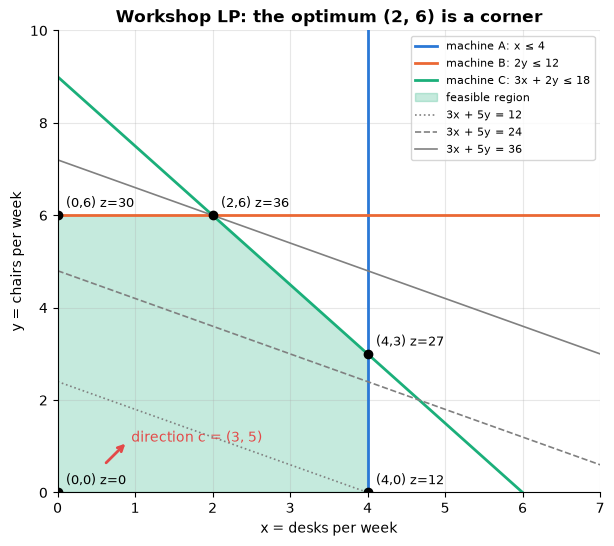

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
xs = np.linspace(0, 7, 400)
ax.plot(xs * 0 + 4, np.linspace(0, 10, 400), label="machine A: x ≤ 4")
ax.plot(xs, xs * 0 + 6, label="machine B: 2y ≤ 12")
ax.plot(xs, (18 - 3 * xs) / 2, label="machine C: 3x + 2y ≤ 18")
feas = V[V.feasible]
centre = feas[["x", "y"]].mean().values
order = np.argsort(np.arctan2(feas.y - centre[1], feas.x - centre[0]))   # sort corners around the centre
poly = feas.iloc[order][["x", "y"]].values
ax.fill(poly[:, 0], poly[:, 1], color=PALETTE[2], alpha=0.25, label="feasible region")
for z_level, ls in [(12, ":"), (24, "--"), (36, "-")]:
    ax.plot(xs, (z_level - 3 * xs) / 5, color="grey", ls=ls, lw=1.2, label=f"3x + 5y = {z_level}")
ax.scatter(feas.x, feas.y, color="black", zorder=5)
for _, r in feas.iterrows():
    ax.annotate(f"({r.x:.0f},{r.y:.0f}) z={r.objective:.0f}", (r.x, r.y), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.annotate("", xy=(0.6 + 0.3, 0.6 + 0.5), xytext=(0.6, 0.6), arrowprops=dict(arrowstyle="->", lw=2, color=PALETTE[7]))
ax.text(0.95, 1.1, "direction c = (3, 5)", color=PALETTE[7])
ax.set(xlim=(0, 7), ylim=(0, 10), xlabel="x = desks per week", ylabel="y = chairs per week",
       title="Workshop LP: the optimum (2, 6) is a corner")
ax.legend(loc="upper right", fontsize=8)
plt.show()

**What just happened?** The green pentagon is the feasible region. The grey objective lines are parallel; the solid one ($z = 36$) touches the region only at the corner **(2, 6)**, which agrees with the solver.

**Why not always enumerate vertices?** With $n$ variables and $m$ constraints there can be up to $\binom{m+n}{n}$ vertices. For 30 variables and 60 constraints that is about $10^{24}$. The simplex method visits only a short path of improving vertices instead.

| situation | picture | solver says |
|---|---|---|
| unique optimum | objective line touches one corner | optimal |
| multiple optima | objective line is parallel to an edge | optimal (one of many) |
| **infeasible** | half-planes have no common point | infeasible |
| **unbounded** | region is open in the direction of $c$ | unbounded |

---
## 3. The simplex method from scratch

> 💬 **In plain English:** start at one corner and keep walking to a better neighbouring corner until none is better.

**Intuition.** Stand on a corner of the polytope. Look along each edge leaving the corner. If some edge goes "uphill" (improves the objective), walk along it to the next corner. When no edge goes uphill, you are at the top: because the region is convex, a local optimum is a global optimum. That is George Dantzig's **simplex method** (1947).

### 3.1 Standard form and the tableau
Add a **slack variable** to each $\le$ constraint to turn it into an equation: $3x + 2y \le 18$ becomes $3x + 2y + s_3 = 18$ with $s_3 \ge 0$ (the unused machine-C hours). Now:
- A **basis** is a set of $m$ variables (one per row); setting all *other* (non-basic) variables to 0 and solving gives a **basic solution**. Basic *feasible* solutions are exactly the vertices.
- At the start, $x = y = 0$ and the slacks form the basis: the corner (0, 0).
- The **tableau** stores the equations plus an objective row $z - 3x - 5y = 0$. A negative entry in the objective row ("reduced cost") means increasing that variable increases $z$.

**One pivot** = one move to a neighbouring corner:
1. **Entering variable:** a column with negative reduced cost. *Dantzig's rule* picks the most negative; **Bland's rule** picks the lowest-index one.
2. **Leaving variable (ratio test):** among rows with a positive entry $a_{ik}$ in that column, pick the smallest $b_i / a_{ik}$. This is how far we can increase the entering variable before some basic variable hits 0. Ties: Bland picks the lowest-index basic variable. No positive entry means we can increase forever: **unbounded**.
3. **Pivot:** divide the pivot row by $a_{rk}$, then subtract multiples of it from every other row so column $k$ becomes a unit vector.

Initial tableau for the workshop (columns $x, y, s_1, s_2, s_3$ | rhs):

```
basis |  x   y   s1  s2  s3 | rhs
 s1   |  1   0   1   0   0  |  4
 s2   |  0   2   0   1   0  | 12
 s3   |  3   2   0   0   1  | 18
  z   | -3  -5   0   0   0  |  0      <- negative entries: increasing x or y helps
```

### 3.2 Two-phase simplex (handling $\ge$ and $=$ rows)
For a $\ge$ or $=$ row there is no obvious starting basis, so we add an **artificial variable** $a_i \ge 0$ to that row. **Phase 1** minimises $\sum a_i$. If the minimum is positive, no feasible point exists (**infeasible**). If it is 0, we have found a vertex of the real problem; we drop the artificial columns and run **Phase 2** on the true objective.

The implementation below is about 90 lines. Every line is commented.

In [6]:
EPS = 1e-9   # tolerance for "zero" in floating-point arithmetic


def pivot(T, r, k):
    """Make column k a unit vector with a 1 in row r (Gauss-Jordan step)."""
    T[r] = T[r] / T[r, k]                        # pivot element becomes 1
    for i in range(T.shape[0]):
        if i != r and abs(T[i, k]) > EPS:
            T[i] = T[i] - T[i, k] * T[r]          # zero out column k in every other row


def run_simplex(T, basis, rule, max_iter, names, trace):
    """Pivot until optimal / unbounded. Last row of T = objective row, last column = rhs."""
    m = T.shape[0] - 1
    seen = {tuple(basis)}                        # bases visited (to detect cycling)
    iters = 0
    while True:
        obj = T[-1, :-1]
        improving = np.where(obj < -EPS)[0]      # columns whose increase raises z
        if len(improving) == 0:
            return "optimal", iters              # no uphill edge -> optimal vertex
        if rule == "bland":
            k = int(improving[0])                # Bland: lowest-index improving column
        else:
            k = int(np.argmin(obj))              # Dantzig: most negative reduced cost
        col = T[:m, k]
        rows = np.where(col > EPS)[0]            # only positive entries limit the step
        if len(rows) == 0:
            return "unbounded", iters            # can increase x_k forever
        ratios = T[rows, -1] / col[rows]         # ratio test
        best = ratios.min()
        ties = [int(rows[i]) for i in range(len(rows)) if ratios[i] <= best + EPS]
        r = min(ties, key=lambda i: basis[i])    # tie-break: lowest-index leaving variable
        if trace is not None:
            trace.append({"enter": names[k], "leave": names[basis[r]], "step": best, "z before": T[-1, -1]})
        pivot(T, r, k)
        basis[r] = k
        iters += 1
        if rule != "bland" and tuple(basis) in seen:
            return "cycling", iters              # same basis again: we are going round in circles
        seen.add(tuple(basis))
        if iters >= max_iter:
            return "iteration limit", iters


def simplex(c, cons, maximize=True, rule="bland", max_iter=10_000, trace=None, snapshots=None):
    """Two-phase tableau simplex. cons = list of (coeffs, '<='|'>='|'=', rhs); all x >= 0.
    Returns a dict with status, x, z, iterations and (for <= rows) shadow prices."""
    c = np.asarray(c, float) * (1 if maximize else -1)    # always maximise internally
    n = len(c)
    rows, senses, rhs = [], [], []
    for a, s, b in cons:                         # make every rhs >= 0
        a, b = [float(v) for v in a], float(b)
        if b < 0:
            a, b, s = [-v for v in a], -b, {"<=": ">=", ">=": "<=", "=": "="}[s]
        rows.append(a); senses.append(s); rhs.append(b)
    m = len(rows)
    n_slack = sum(s != "=" for s in senses)      # one slack/surplus per inequality
    n_art = sum(s != "<=" for s in senses)       # one artificial per >= or = row
    T = np.zeros((m + 1, n + n_slack + n_art + 1))
    names = [f"x{j+1}" for j in range(n)] + [f"s{i+1}" for i in range(n_slack)] + [f"a{i+1}" for i in range(n_art)]
    basis, art_cols, slack_col = [0] * m, [], {}
    si, ai = n, n + n_slack
    for i, (a, s, b) in enumerate(zip(rows, senses, rhs)):
        T[i, :n], T[i, -1] = a, b
        if s == "<=":                            # a.x + s = b, slack starts in the basis
            T[i, si] = 1; basis[i] = si; slack_col[i] = si; si += 1
        elif s == ">=":                          # a.x - s + art = b
            T[i, si] = -1; si += 1
            T[i, ai] = 1; basis[i] = ai; art_cols.append(ai); ai += 1
        else:                                    # a.x + art = b
            T[i, ai] = 1; basis[i] = ai; art_cols.append(ai); ai += 1
    iters = 0
    if art_cols:                                 # ---------- Phase 1: minimise sum of artificials
        T[-1, :] = 0
        T[-1, art_cols] = 1.0
        for i in range(m):
            if basis[i] in art_cols:
                T[-1] -= T[i]                    # express the phase-1 objective in non-basic terms
        _, it = run_simplex(T, basis, "bland", max_iter, names, trace)
        iters += it
        if -T[-1, -1] > 1e-7:                    # artificials cannot all be 0
            return {"status": "infeasible", "iterations": iters}
        keep = []
        for i in range(m):                       # pivot any zero-level artificial out of the basis
            if basis[i] in art_cols:
                cand = [j for j in range(n + n_slack) if abs(T[i, j]) > EPS]
                if cand:
                    pivot(T, i, cand[0]); basis[i] = cand[0]; keep.append(i)
                # else: the row is redundant (a combination of other rows) and is dropped
            else:
                keep.append(i)
        T = np.delete(np.vstack([T[keep], T[-1:]]), art_cols, axis=1)
        basis = [basis[i] for i in keep]
        names = [nm for j, nm in enumerate(names) if j not in art_cols]
        m = len(keep)
    T[-1, :] = 0                                 # ---------- Phase 2: the real objective
    T[-1, :n] = -c                               # z - c.x = 0
    for i in range(m):
        if abs(T[-1, basis[i]]) > 0:
            T[-1] -= T[-1, basis[i]] * T[i]      # make reduced costs of basic columns zero
    if snapshots is not None:
        snapshots.append((T.copy(), list(basis), list(names)))
    status, it = run_simplex(T, basis, rule, max_iter, names, trace)
    iters += it
    if status != "optimal":
        return {"status": status, "iterations": iters}
    x = np.zeros(T.shape[1] - 1)
    for i in range(m):
        x[basis[i]] = T[i, -1]                   # basic variables take the rhs values
    shadow = {i: T[-1, col] for i, col in slack_col.items()}   # reduced cost of slack i = dual value y_i
    z = T[-1, -1]
    return {"status": "optimal", "x": x[:n], "z": z if maximize else -z, "iterations": iters,
            "shadow_prices": shadow, "tableau": T, "basis": basis, "names": names}


def show_tableau(T, basis, names):
    """Pretty-print a tableau as a DataFrame."""
    df = pd.DataFrame(T, columns=names + ["rhs"], index=[names[b] for b in basis] + ["z"])
    return df.round(3)


for rule in ["dantzig", "bland"]:
    trace = []
    res = simplex(workshop_c, workshop_cons, rule=rule, trace=trace)
    print(f"--- {rule} rule: {res['iterations']} pivots, x = {res['x']}, z = {res['z']:.1f}")
    print(pd.DataFrame(trace).to_string(index=False))
print("\nFinal tableau (Bland):")
print(show_tableau(res["tableau"], res["basis"], res["names"]))

--- dantzig rule: 2 pivots, x = [2. 6.], z = 36.0
enter leave  step  z before
   x2    s2   6.0       0.0
   x1    s3   2.0      30.0
--- bland rule: 3 pivots, x = [2. 6.], z = 36.0
enter leave  step  z before
   x1    s1   4.0       0.0
   x2    s3   3.0      12.0
   s1    s2   2.0      27.0

Final tableau (Bland):
     x1   x2   s1     s2     s3   rhs
x1  1.0  0.0  0.0 -0.333  0.333   2.0
s1  0.0  0.0  1.0  0.333 -0.333   2.0
x2  0.0  1.0  0.0  0.500  0.000   6.0
z   0.0  0.0  0.0  1.500  1.000  36.0


**What just happened?**
- With **Dantzig's rule** the method went (0,0) → (0,6) → (2,6): $y$ (reduced cost −5) entered first, the ratio test ($12/2 = 6$ beats $18/2 = 9$) made $s_2$ leave, then $x$ entered and $s_3$ left. **2 pivots**.
- With **Bland's rule**, $x$ (lowest index) entered first and the path was (0,0) → (4,0) → (4,3) → (2,6): **3 pivots**. Both reach $z = 36$ at $(2, 6)$.
- In the final tableau the objective row has no negative entries, so no edge goes uphill. The entries under the slack columns, $0$, $1.5$ and $1$, are the **shadow prices** of the three machines. We will meet them again in Section 4.

### 3.3 Checking against HiGHS on random LPs
A from-scratch solver is only trustworthy after it agrees with a reference on many cases, including infeasible and unbounded ones. We generate 600 random LPs mixing $\le$, $\ge$ and $=$ rows, maximisation and minimisation, and compare the status and the optimal value with `linprog`.

In [7]:
def random_lp(rng):
    n, m = rng.randint(1, 6), rng.randint(1, 6)
    if rng.random() < 0.4:                       # "nice" LPs: positive A, positive b -> usually optimal
        cons = [([rng.randint(0, 6) for _ in range(n)], "<=", rng.randint(1, 30)) for _ in range(m)]
        cons.append(([1] * n, "<=", 50))         # keeps the region bounded
    else:                                        # anything goes
        cons = [([rng.randint(-5, 5) for _ in range(n)], rng.choice(["<=", "<=", ">=", "="]), rng.randint(-10, 20))
                for _ in range(m)]
    c = [rng.randint(-5, 8) for _ in range(n)]
    return c, cons, rng.random() < 0.5


rng = random.Random(7)
outcomes = Counter()
for t in range(600):
    c, cons, mx = random_lp(rng)
    ours = simplex(c, cons, maximize=mx)
    st, z_ref, _ = scipy_lp(c, cons, maximize=mx)
    assert ours["status"] == st, (t, ours["status"], st)
    if st == "optimal":
        assert abs(ours["z"] - z_ref) <= 1e-6 * max(1, abs(z_ref)), (t, ours["z"], z_ref)
    outcomes[st] += 1
    CHECKS["simplex vs HiGHS"] += 1
print("statuses seen:", dict(outcomes))
print("all", sum(outcomes.values()), "random LPs agree with scipy.optimize.linprog(method='highs')")

statuses seen: {'optimal': 331, 'infeasible': 167, 'unbounded': 102}
all 600 random LPs agree with scipy.optimize.linprog(method='highs')


**What just happened?** All 600 random LPs gave the same status, and every optimal one gave the same objective value (to $10^{-6}$), across optimal, infeasible and unbounded cases.

> ⚠️ **Common mistake (a real one we hit while building this notebook):** solvers run a **presolve** step that simplifies the model first. When presolve detects that something is wrong it may only know "infeasible *or* unbounded", and the reported status can be misleading. The cell below shows one of our random LPs: it is clearly feasible (the point $x_4 = 2$ satisfies every row) and unbounded, yet with presolve on the reported status is different. That is why `scipy_lp` above turns presolve off. In practice: when a solver says "infeasible", check by re-solving without presolve or by testing a point you believe is feasible.

In [8]:
c_bad = [-5, 2, -4, -3]                                          # minimise this
A_bad = [[-4, 3, -5, 1], [3, 1, 5, -5], [1, 5, -4, -3]]           # all rows written as <=
b_bad = [4, -8, 1]
print("is x = (0, 0, 0, 2) feasible?", bool(np.all(np.array(A_bad) @ [0, 0, 0, 2] <= b_bad)))
for presolve in [True, False]:
    r = linprog(c_bad, A_ub=A_bad, b_ub=b_bad, method="highs", options={"presolve": presolve})
    print(f"presolve={presolve!s:5}: status {r.status} -> {r.message}")
cons_bad = [(a, "<=", b) for a, b in zip(A_bad, b_bad)]
print("our simplex:", simplex(c_bad, cons_bad, maximize=False)["status"])

is x = (0, 0, 0, 2) feasible? True
presolve=True : status 2 -> The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)
presolve=False: status 3 -> The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)
our simplex: unbounded


### 3.4 Degeneracy and cycling: why Bland's rule matters
A vertex is **degenerate** when more constraints than necessary pass through it (a basic variable equals 0). A pivot there can change the basis without moving ($\text{step} = 0$). With Dantzig's rule the method can then visit the same bases forever: **cycling**. The classic example (Chvátal, *Linear Programming*, 1983) is
$$\max\; 10x_1 - 57x_2 - 9x_3 - 24x_4 \;\text{ s.t. }\; \tfrac12 x_1 - \tfrac{11}{2}x_2 - \tfrac52 x_3 + 9x_4 \le 0,\;\; \tfrac12 x_1 - \tfrac32 x_2 - \tfrac12 x_3 + x_4 \le 0,\;\; x_1 \le 1.$$
**Bland's rule** (lowest-index entering and leaving) is proven never to cycle (Bland, 1977).

In [9]:
chvatal_c = [10, -57, -9, -24]
chvatal_cons = [([0.5, -5.5, -2.5, 9], "<=", 0), ([0.5, -1.5, -0.5, 1], "<=", 0), ([1, 0, 0, 0], "<=", 1)]
for rule in ["dantzig", "bland"]:
    trace = []
    res = simplex(chvatal_c, chvatal_cons, rule=rule, trace=trace)
    df = pd.DataFrame(trace)
    print(f"--- {rule}: status = {res['status']} after {res['iterations']} pivots", f"z = {res['z']:.0f}, x = {res['x']}" if res["status"] == "optimal" else "")
    print(df[["enter", "leave", "step"]].T.to_string(header=False))
st, z_ref, x_ref = scipy_lp(chvatal_c, chvatal_cons)
print("HiGHS:", st, z_ref, x_ref)

--- dantzig: status = cycling after 6 pivots 
enter   x1   x2   x3   x4   s1   s2
leave   s1   s2   x1   x2   x3   x4
step   0.0  0.0  0.0  0.0  0.0  0.0
--- bland: status = optimal after 7 pivots z = 1, x = [1. 0. 1. 0.]
enter   x1   x2   x3   x4   s1   x1   x3
leave   s1   s2   x1   x2   x3   x4   s3
step   0.0  0.0  0.0  0.0  0.0  0.0  1.0
HiGHS: optimal 1.0 [1. 0. 1. 0.]


**What just happened?** With Dantzig's rule every one of the 6 pivots had **step 0** (a degenerate vertex), and after 6 pivots the basis was back to the starting one ($s_1, s_2, s_3$): an infinite loop, which our code detects and stops. Bland's rule escapes after 7 pivots and reaches the optimum $z = 1$ at $x = (1, 0, 1, 0)$, matching HiGHS.

### 3.5 How many pivots? The Klee–Minty cube
Each pivot costs $O(mn)$ arithmetic (update the whole tableau). The number of pivots is usually a small multiple of $m$ in practice, but **Klee and Minty (1972)** built a squashed $n$-dimensional cube on which Dantzig's rule visits all $2^n$ corners:
$$\max \sum_{j=1}^n 2^{n-j} x_j \quad\text{s.t.}\quad 2\sum_{j=1}^{i-1} 2^{i-j} x_j + x_i \le 5^i,\; i = 1..n,\; x \ge 0.$$

 n  Dantzig pivots  2^n - 1  Bland pivots
 2               3        3             3
 3               7        7             5
 4              15       15             9
 5              31       31            15
 6              63       63            25
 7             127      127            41
 8             255      255            67
 9             511      511           109
10            1023     1023           177


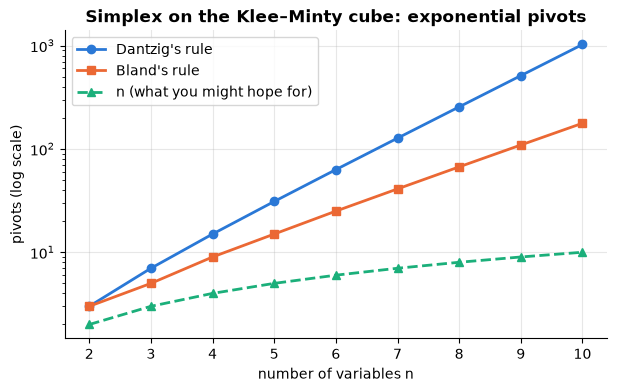

In [10]:
def klee_minty(n):
    c = [2 ** (n - j) for j in range(1, n + 1)]
    cons = []
    for i in range(1, n + 1):
        a = [2 ** (i - j + 1) if j < i else (1 if j == i else 0) for j in range(1, n + 1)]
        cons.append((a, "<=", 5 ** i))
    return c, cons


rows = []
for n in range(2, 11):
    c, cons = klee_minty(n)
    d, b = simplex(c, cons, rule="dantzig"), simplex(c, cons, rule="bland")
    assert abs(d["z"] - 5 ** n) < 1e-6 * 5 ** n and abs(b["z"] - 5 ** n) < 1e-6 * 5 ** n   # optimum is 5^n
    rows.append({"n": n, "Dantzig pivots": d["iterations"], "2^n - 1": 2 ** n - 1, "Bland pivots": b["iterations"]})
km = pd.DataFrame(rows)
print(km.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(km.n, km["Dantzig pivots"], "o-", label="Dantzig's rule")
ax.semilogy(km.n, km["Bland pivots"], "s-", label="Bland's rule")
ax.semilogy(km.n, km.n, "^--", label="n (what you might hope for)")
ax.set(xlabel="number of variables n", ylabel="pivots (log scale)", title="Simplex on the Klee–Minty cube: exponential pivots")
ax.legend(); plt.show()

**What just happened?** Dantzig's rule needed exactly $2^n - 1$ pivots (1,023 for $n = 10$): it visited every corner of the cube. Bland's rule also grows exponentially here (it has its own bad examples). Even so, simplex is the method of choice in practice; Spielman and Teng (2004) explained why with **smoothed analysis**: after tiny random perturbations of the data, the expected number of pivots is polynomial.

| algorithm | worst case | in practice |
|---|---|---|
| simplex (any known pivot rule) | exponential (Klee–Minty-type examples) | very fast; warm-starts well, which branch-and-bound needs |
| ellipsoid method (Khachiyan, 1979) | **polynomial**: first proof that LP $\in$ **P** | slow, mostly of theoretical value |
| interior-point methods (Karmarkar, 1984) | polynomial, about $O(\sqrt{n}\,\log(1/\varepsilon))$ iterations | excellent for very large sparse LPs |

**Complexity of one tableau pivot:** $O(mn)$ time and $O(mn)$ space for the dense tableau. Production solvers such as HiGHS use the **revised simplex method** with sparse LU factorisations instead of a dense tableau.

> 🎓 **Exam / interview tip:** "Is linear programming in P?" Yes (ellipsoid, 1979; interior point, 1984). "Is the simplex method polynomial?" No known pivot rule is; it is exponential in the worst case. Keep these two statements separate.

---
## 4. LP duality and shadow prices

> 💬 **In plain English:** every "maximise profit" problem has a twin "price the resources" problem with the same answer, and those prices tell you what each resource is worth.

**Intuition.** Suppose a competitor wants to **rent** all of the workshop's machine hours. They offer $y_1, y_2, y_3$ dollars per hour for machines A, B, C. To make the workshop accept, renting must pay at least as much as using the hours to build: a desk uses 1 hour of A and 3 of C and earns 3, so $y_1 + 3y_3 \ge 3$; a chair uses 2 hours of B and 2 of C and earns 5, so $2y_2 + 2y_3 \ge 5$. The competitor wants to pay as little as possible: minimise $4y_1 + 12y_2 + 18y_3$. That rental problem is the **dual** LP.

**Definition.** For the **primal** $\max\{c^\top x : Ax \le b, x \ge 0\}$ the **dual** is
$$\min\; b^\top y \quad\text{s.t.}\quad A^\top y \ge c,\; y \ge 0.$$
- **Weak duality:** for any primal-feasible $x$ and dual-feasible $y$, $c^\top x \le b^\top y$. (Proof: $c^\top x \le (A^\top y)^\top x = y^\top (Ax) \le y^\top b$.)
- **Strong duality:** if the primal has an optimum, so does the dual, and the optimal values are **equal**.
- **Complementary slackness:** at optimality, $y_i > 0$ only if constraint $i$ is tight (no unused hours), and $x_j > 0$ only if dual constraint $j$ is tight.
- The optimal $y_i$ is the **shadow price** of resource $i$: the increase in the optimal objective per extra unit of $b_i$ (as long as the basis stays optimal).

| primal (max) | dual (min) |
|---|---|
| $n$ variables $x_j \ge 0$ | $n$ constraints $\ge$ |
| $m$ constraints $\le$ | $m$ variables $y_i \ge 0$ |
| objective vector $c$ | right-hand side $c$ |
| right-hand side $b$ | objective vector $b$ |

In [11]:
def dual_of(c, cons):
    """Dual of max{c.x : Ax <= b, x >= 0}  ->  min{b.y : A^T y >= c, y >= 0}, in the same (coeffs, sense, rhs) format."""
    A = np.array([a for a, s, b in cons], float)
    b = [rhs for a, s, rhs in cons]
    assert all(s == "<=" for a, s, rhs in cons), "canonical form expected"
    dual_cons = [([float(v) for v in A[:, j]], ">=", c[j]) for j in range(len(c))]
    return b, dual_cons


dual_c, dual_cons = dual_of(workshop_c, workshop_cons)
print("dual: minimise", dual_c, "subject to")
for a, s, r in dual_cons:
    print("   ", a, s, r)
primal = simplex(workshop_c, workshop_cons)
dual = simplex(dual_c, dual_cons, maximize=False)
print(f"\nprimal optimum = {primal['z']:.4f} at x = {primal['x']}")
print(f"dual   optimum = {dual['z']:.4f} at y = {dual['x']}")
print("shadow prices read from the final primal tableau:", {f"machine {'ABC'[i]}": round(float(v), 4) for i, v in primal["shadow_prices"].items()})

# The same numbers from HiGHS: linprog minimises -c.x, its marginals are d(objective)/d(b) <= 0
res = linprog(-np.array(workshop_c), A_ub=[a for a, s, b in workshop_cons], b_ub=[b for a, s, b in workshop_cons], method="highs")
print("shadow prices from linprog (-marginals):", -res.ineqlin.marginals)

# Complementary slackness
A = np.array([a for a, s, b in workshop_cons], float); b = np.array([r for a, s, r in workshop_cons], float)
slack = b - A @ primal["x"]
print("\nunused hours (primal slack):", slack, "  y_i * slack_i:", dual["x"] * slack)

dual: minimise [4, 12, 18] subject to
    [1.0, 0.0, 3.0] >= 3
    [0.0, 2.0, 2.0] >= 5

primal optimum = 36.0000 at x = [2. 6.]
dual   optimum = 36.0000 at y = [0.  1.5 1. ]
shadow prices read from the final primal tableau: {'machine A': 0.0, 'machine B': 1.5, 'machine C': 1.0}
shadow prices from linprog (-marginals): [0.  1.5 1. ]

unused hours (primal slack): [2. 0. 0.]   y_i * slack_i: [0. 0. 0.]


**What just happened?**
- The dual optimum is **36**, exactly the primal optimum (**strong duality**), at $y = (0, 1.5, 1)$.
- The same numbers sit in the primal's final tableau under the slack columns, and HiGHS reports them as (negated) marginals.
- Machine A has 2 unused hours, so its shadow price is **0**: an extra hour of a machine you do not fully use is worth nothing. Each product $y_i \cdot \text{slack}_i$ is 0, which is complementary slackness.

Let us check the meaning of a shadow price directly: add one hour to each machine and re-solve.

In [12]:
base = simplex(workshop_c, workshop_cons)["z"]
for i, name in enumerate("ABC"):
    cons2 = [(a, s, r + (1 if k == i else 0)) for k, (a, s, r) in enumerate(workshop_cons)]
    print(f"+1 hour on machine {name}: profit {base:.1f} -> {simplex(workshop_c, cons2)['z']:.1f}   (shadow price {primal['shadow_prices'][i]:.1f})")

# Weak duality on random feasible pairs, strong duality on random LPs
rng = np.random.default_rng(0)
for _ in range(2000):                                 # random primal-feasible x and dual-feasible y
    x = rng.uniform(0, 1) * np.array([rng.uniform(0, 4), rng.uniform(0, 6)])
    if np.all(A @ x <= b):
        y = np.array([0, 1.5, 1]) + rng.uniform(0, 3, 3)   # anything >= a dual-feasible point stays feasible
        assert np.dot(workshop_c, x) <= np.dot(b, y) + 1e-9
        CHECKS["weak duality"] += 1
rr = random.Random(3)
for _ in range(300):
    n, m = rr.randint(1, 6), rr.randint(1, 6)
    cons = [([rr.randint(0, 6) for _ in range(n)], "<=", rr.randint(1, 30)) for _ in range(m)] + [([1] * n, "<=", 40)]
    c = [rr.randint(-3, 9) for _ in range(n)]
    p = simplex(c, cons); dc, dcons = dual_of(c, cons); d = simplex(dc, dcons, maximize=False)
    assert abs(p["z"] - d["z"]) < 1e-7 * max(1, abs(p["z"]))
    CHECKS["strong duality"] += 1
print(f"\nweak duality held on {CHECKS['weak duality']} random pairs; strong duality held on {CHECKS['strong duality']} random LPs")

+1 hour on machine A: profit 36.0 -> 36.0   (shadow price 0.0)
+1 hour on machine B: profit 36.0 -> 37.5   (shadow price 1.5)
+1 hour on machine C: profit 36.0 -> 37.0   (shadow price 1.0)



weak duality held on 1969 random pairs; strong duality held on 300 random LPs


**What just happened?** An extra hour on machine B raised profit by exactly 1.5, on C by 1, and on A by 0: the shadow prices predicted the re-solved optimum. Weak and strong duality held on every random test.

> ⚠️ **Common mistake:** reading a shadow price as valid for *any* change of $b_i$. It is valid only while the same basis stays optimal (Section 7 measures that range). Also, signs differ between solvers: `linprog` minimises, so for a maximisation problem you must negate its marginals.

> 🎓 **Exam / interview tip:** the dual of the dual is the primal. A quick consistency check in exams: if the primal is unbounded, the dual must be infeasible (by weak duality), and vice versa (it is possible for both to be infeasible).

---
## 5. Integer programming and branch-and-bound

> 💬 **In plain English:** when answers must be whole numbers, split the problem into smaller cases and skip any case that cannot beat the best answer found so far.

Many decisions are whole numbers or yes/no: open a warehouse or not, how many GPUs to buy, which items to pack. An **integer linear program (ILP)** is an LP plus the constraint that (some or all) variables are integers; with only some integer variables it is a **mixed-integer linear program (MILP)**. With binary variables the model can express "choose", "if-then" and "either-or" logic.

**Complexity.** LP is in **P**, but ILP is **NP-hard** (0/1 integer programming is one of Karp's 21 NP-complete problems, 1972; see [notebook 02](02_np_completeness_and_reductions.ipynb)). So no known algorithm is polynomial in the worst case, and we use clever exhaustive search.

### 5.1 Why rounding the LP fails
$$\max\; 21x + 11y \quad\text{s.t.}\quad 7x + 4y \le 13,\quad x, y \ge 0 \text{ integer.}$$
The **LP relaxation** (drop integrality) has optimum $x = 13/7 \approx 1.857, y = 0$ with $z = 39$.

| strategy | point | feasible? | $z$ |
|---|---|---|---|
| LP relaxation | (1.857, 0) | not integer | 39 |
| round to nearest | (2, 0) | **no**: $14 > 13$ | |
| round down | (1, 0) | yes | 21 |
| true integer optimum | (0, 3) | yes | **33** |

Rounding down gives 21, far from the true optimum 33, and the optimum (0, 3) is nowhere near the LP point.

LP relaxation: x = [1.857 0.   ], z = 39.00
integer optimum (brute force): (0, 3), z = 33


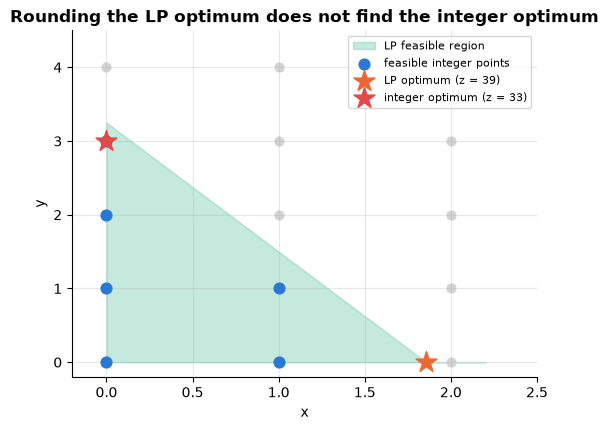

In [13]:
ex_c, ex_cons = [21, 11], [([7, 4], "<=", 13)]
lp = simplex(ex_c, ex_cons)
pts = [(x, y) for x in range(3) for y in range(5) if 7 * x + 4 * y <= 13]       # brute force over the lattice
best_int = max(pts, key=lambda p: 21 * p[0] + 11 * p[1])
print(f"LP relaxation: x = {lp['x'].round(3)}, z = {lp['z']:.2f}")
print(f"integer optimum (brute force): {best_int}, z = {21 * best_int[0] + 11 * best_int[1]}")

fig, ax = plt.subplots(figsize=(6, 4.5))
xs = np.linspace(0, 2.2, 50)
ax.fill_between(xs, 0, np.clip((13 - 7 * xs) / 4, 0, None), color=PALETTE[2], alpha=0.25, label="LP feasible region")
gx, gy = np.meshgrid(range(3), range(5))
ax.scatter(gx, gy, color="lightgrey", s=40)
ax.scatter(*zip(*pts), color=PALETTE[0], s=60, label="feasible integer points", zorder=3)
ax.scatter(*lp["x"], marker="*", s=250, color=PALETTE[1], label="LP optimum (z = 39)", zorder=4)
ax.scatter(*best_int, marker="*", s=250, color=PALETTE[7], label="integer optimum (z = 33)", zorder=4)
ax.set(xlabel="x", ylabel="y", title="Rounding the LP optimum does not find the integer optimum", xlim=(-0.2, 2.5), ylim=(-0.2, 4.5))
ax.legend(fontsize=8); plt.show()

### 5.2 Branch-and-bound
**Intuition:** solve the LP relaxation. If the answer happens to be integral, done. Otherwise pick a fractional variable, e.g. $x = 1.857$, and **branch** into two subproblems that both exclude it: one with $x \le 1$ and one with $x \ge 2$. Every integer solution lies in one of the two. Recurse. Two facts make this much faster than enumerating:
- **Bound:** a subproblem's LP value is an *upper bound* (for maximisation) on any integer solution inside it. If that bound is no better than the best integer solution found so far (the **incumbent**), the whole subtree is **pruned**.
- **Infeasible** subproblems are pruned too.

```
                 root: LP z=39, x=1.857
                /                      \
        x <= 1                          x >= 2
   LP z=37.5, y=1.5                  infeasible (prune)
      /          \
  y <= 1        y >= 2
  z=32 (x=1,y=1)  LP z=37, x=0.714
  integer!         ... keep branching
```

The implementation uses our own `simplex` for every LP relaxation and records each node so we can draw the tree.

In [14]:
def branch_and_bound(c, cons, int_vars, maximize=True, tol=1e-6):
    """Depth-first branch-and-bound for (M)ILPs. int_vars = indices that must be integer.
    Uses our simplex() for the LP relaxations. Returns (best value, best x, list of node records)."""
    sign = 1 if maximize else -1
    best_val, best_x = -math.inf, None           # incumbent (in "maximise" units)
    nodes = []
    stack = [(0, None, [], "root")]              # (node id, parent id, extra constraints, label)
    next_id = 1
    while stack:
        nid, parent, extra, label = stack.pop()
        res = simplex(c, cons + extra, maximize=maximize)
        rec = {"node": nid, "parent": parent, "branch": label, "lp_value": None, "outcome": None}
        nodes.append(rec)
        if res["status"] != "optimal":
            rec["outcome"] = "infeasible"
            continue
        val, x = sign * res["z"], res["x"]
        rec["lp_value"] = res["z"]
        if val <= best_val + tol:                # bound: cannot beat the incumbent
            rec["outcome"] = "pruned by bound"
            continue
        frac = [(j, x[j]) for j in int_vars if abs(x[j] - round(x[j])) > tol]
        if not frac:                             # integral -> new incumbent
            best_val, best_x = val, np.round(x, 9)
            rec["outcome"] = "new incumbent"
            continue
        j, v = max(frac, key=lambda t: min(t[1] - math.floor(t[1]), math.ceil(t[1]) - t[1]))   # most fractional
        e = [0] * len(c); e[j] = 1
        rec["outcome"] = f"branch on x{j+1} = {v:.3f}"
        stack.append((next_id, nid, extra + [(e, ">=", math.ceil(v))], f"x{j+1} >= {math.ceil(v)}"))
        stack.append((next_id + 1, nid, extra + [(e, "<=", math.floor(v))], f"x{j+1} <= {math.floor(v)}"))
        next_id += 2
    return (sign * best_val if best_x is not None else None), best_x, nodes


val, xb, nodes = branch_and_bound(ex_c, ex_cons, int_vars=[0, 1])
print("branch-and-bound optimum:", val, "at", xb)
print(pd.DataFrame(nodes).to_string(index=False))

branch-and-bound optimum: 33.0 at [0. 3.]
 node  parent  branch  lp_value              outcome
    0     NaN    root     39.00 branch on x1 = 1.857
    2     0.0 x1 <= 1     37.50 branch on x2 = 1.500
    4     2.0 x2 <= 1     32.00        new incumbent
    3     2.0 x2 >= 2     37.00 branch on x1 = 0.714
    6     3.0 x1 <= 0     35.75 branch on x2 = 3.250
    8     6.0 x2 <= 3     33.00        new incumbent
    7     6.0 x2 >= 4       NaN           infeasible
    5     3.0 x1 >= 1       NaN           infeasible
    1     0.0 x1 >= 2       NaN           infeasible


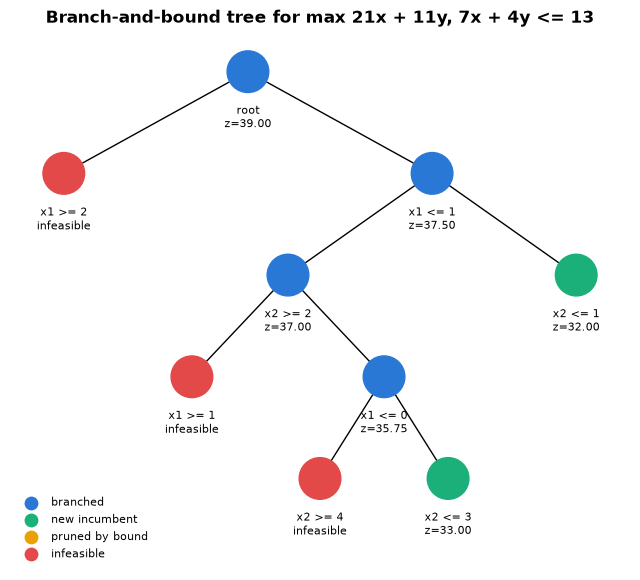

In [15]:
def draw_bb_tree(nodes, title):
    """Draw a branch-and-bound tree: leaves left to right, parents centred above children."""
    G = nx.DiGraph()
    for r in nodes:
        G.add_node(r["node"], **r)
        if r["parent"] is not None:
            G.add_edge(r["parent"], r["node"])
    pos, counter = {}, [0]
    def place(v, depth):
        kids = sorted(G.successors(v))
        if not kids:
            pos[v] = (counter[0], -depth); counter[0] += 1
        else:
            for k in kids: place(k, depth + 1)
            pos[v] = (np.mean([pos[k][0] for k in kids]), -depth)
    place(0, 0)
    colour = {"new incumbent": PALETTE[2], "infeasible": PALETTE[7], "pruned by bound": PALETTE[3]}
    cols = [colour.get(G.nodes[v]["outcome"], PALETTE[0]) for v in G.nodes]
    labels = {v: (f"{G.nodes[v]['branch']}\n" + (f"z={G.nodes[v]['lp_value']:.2f}" if G.nodes[v]["lp_value"] is not None else "infeasible"))
              for v in G.nodes}
    fig, ax = plt.subplots(figsize=(max(6, 1.6 * counter[0]), 1.4 * (1 + max(-p[1] for p in pos.values()))))
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=False)
    nx.draw_networkx_nodes(G, pos, node_color=cols, node_size=900, ax=ax)
    for v, (px, py) in pos.items():
        ax.text(px, py - 0.32, labels[v], ha="center", va="top", fontsize=8)
    for name, col in [("branched", PALETTE[0]), ("new incumbent", PALETTE[2]), ("pruned by bound", PALETTE[3]), ("infeasible", PALETTE[7])]:
        ax.scatter([], [], color=col, label=name, s=80)
    ax.legend(loc="lower left", fontsize=8, frameon=False)
    ax.set_title(title); ax.axis("off")
    ax.set_ylim(min(p[1] for p in pos.values()) - 0.9, 0.4)
    plt.show()


draw_bb_tree(nodes, "Branch-and-bound tree for max 21x + 11y, 7x + 4y <= 13")

**What just happened?** Read the table and the tree together. The root LP gave $z = 39$ with $x$ fractional, so we branched on $x$. The search went down the $x \le 1$ side first, found integer solutions, and each one became the new incumbent if it was better (green), and contradictory branches were infeasible (red). In this tiny example no node was "pruned by bound" (orange); the knapsack below has some. The final answer is **33 at (0, 3)**, matching brute force.

### 5.3 Knapsack and facility location
**0/1 knapsack:** choose items to maximise value subject to a weight limit; $x_j \in \{0,1\}$. We compare branch-and-bound with the dynamic-programming solution from [`dsa/09`](../dsa/09_dynamic_programming.ipynb) and with `scipy.optimize.milp`.

**Uncapacitated facility location:** open some of 4 candidate warehouses (fixed cost $f_i$, binary $y_i$) and assign each of 8 customers to an open warehouse (cost $d_{ij}$, continuous $x_{ij} \in [0,1]$):
$$\min \sum_i f_i y_i + \sum_{i,j} d_{ij} x_{ij}\quad\text{s.t.}\quad \sum_i x_{ij} = 1\;\forall j,\qquad x_{ij} \le y_i\;\forall i,j.$$
Only the $y_i$ need to be integer (a MILP): once the open set is fixed, each customer simply goes to the cheapest open warehouse.

In [16]:
def knapsack_dp(values, weights, W):
    best = [0] * (W + 1)                         # best[w] = best value with capacity w
    for v, wt in zip(values, weights):
        for w in range(W, wt - 1, -1):           # backwards so each item is used at most once
            best[w] = max(best[w], best[w - wt] + v)
    return best[W]


def knapsack_milp(values, weights, W):
    n = len(values)
    res = milp(c=-np.array(values, float), constraints=LinearConstraint([weights], -np.inf, W),
               integrality=np.ones(n), bounds=Bounds(0, 1))
    return -res.fun


values = [60, 100, 120, 80, 30, 90, 70, 40]
weights = [10, 20, 30, 15, 5, 25, 20, 10]
W = 70
ks_cons = [(weights, "<=", W)] + [([1 if k == j else 0 for k in range(8)], "<=", 1) for j in range(8)]
val, xb, ks_nodes = branch_and_bound(values, ks_cons, int_vars=list(range(8)))
print(f"knapsack: B&B = {val:.0f} (chosen items {np.flatnonzero(xb > 0.5).tolist()}), DP = {knapsack_dp(values, weights, W)}, "
      f"milp = {knapsack_milp(values, weights, W):.0f}; B&B explored {len(ks_nodes)} nodes vs 2^8 = 256 subsets")
print("outcomes:", dict(Counter(r["outcome"].split(" on")[0] for r in ks_nodes)))

# random knapsacks: B&B == DP == milp
rr = random.Random(11)
for _ in range(40):
    n = rr.randint(1, 8)
    vals, wts = [rr.randint(1, 50) for _ in range(n)], [rr.randint(1, 20) for _ in range(n)]
    Wr = rr.randint(1, 60)
    cons = [(wts, "<=", Wr)] + [([1 if k == j else 0 for k in range(n)], "<=", 1) for j in range(n)]
    v_bb, _, _ = branch_and_bound(vals, cons, int_vars=list(range(n)))
    assert abs(v_bb - knapsack_dp(vals, wts, Wr)) < 1e-6 and abs(v_bb - knapsack_milp(vals, wts, Wr)) < 1e-6
    CHECKS["B&B knapsack vs DP vs milp"] += 1
print("40 random knapsacks: branch-and-bound = DP = milp")

knapsack: B&B = 340 (chosen items [0, 1, 3, 4, 6]), DP = 340, milp = 340; B&B explored 7 nodes vs 2^8 = 256 subsets
outcomes: {'branch': 3, 'new incumbent': 2, 'pruned by bound': 2}


40 random knapsacks: branch-and-bound = DP = milp


In [17]:
rng = np.random.default_rng(5)
F, C = 4, 8                                          # facilities, customers
fixed = np.array([120, 90, 150, 100])
fac_xy, cust_xy = rng.uniform(0, 10, (F, 2)), rng.uniform(0, 10, (C, 2))
dist = np.round(np.linalg.norm(fac_xy[:, None] - cust_xy[None], axis=2) * 10)   # assignment cost d_ij
nv = F + F * C                                       # variables: y_0..y_3, then x_ij
yi = lambda i: i
xi = lambda i, j: F + i * C + j
c_fl = list(fixed) + [dist[i, j] for i in range(F) for j in range(C)]
fl_cons = []
for j in range(C):                                   # each customer fully assigned
    a = [0] * nv
    for i in range(F): a[xi(i, j)] = 1
    fl_cons.append((a, "=", 1))
for i in range(F):
    for j in range(C):                               # x_ij <= y_i  (only ship from open sites)
        a = [0] * nv; a[xi(i, j)] = 1; a[yi(i)] = -1
        fl_cons.append((a, "<=", 0))
    a = [0] * nv; a[yi(i)] = 1
    fl_cons.append((a, "<=", 1))                     # y_i <= 1

val_bb, x_bb, fl_nodes = branch_and_bound(c_fl, fl_cons, int_vars=list(range(F)), maximize=False)

def brute_force_fl():                                # try every non-empty set of open facilities
    best = math.inf
    for mask in range(1, 2 ** F):
        openf = [i for i in range(F) if mask >> i & 1]
        best = min(best, fixed[openf].sum() + dist[openf].min(axis=0).sum())
    return best

A_fl = np.array([a for a, s, r in fl_cons], float)
lb = np.array([r if s == "=" else -np.inf for a, s, r in fl_cons]); ub = np.array([r for a, s, r in fl_cons], float)
res = milp(c_fl, constraints=LinearConstraint(A_fl, lb, ub), integrality=[1] * F + [0] * (F * C), bounds=Bounds(0, np.inf))
lp_relax = simplex(c_fl, fl_cons, maximize=False)["z"]
# weaker "aggregated" formulation: sum_j x_ij <= C * y_i instead of the F*C constraints x_ij <= y_i
agg_cons = fl_cons[:C] + [([C * -1 if k == yi(i) else (1 if F + i * C <= k < F + (i + 1) * C else 0) for k in range(nv)], "<=", 0)
                          for i in range(F)] + [([1 if k == yi(i) else 0 for k in range(nv)], "<=", 1) for i in range(F)]
lp_relax_agg = simplex(c_fl, agg_cons, maximize=False)["z"]
val_agg, _, agg_nodes = branch_and_bound(c_fl, agg_cons, int_vars=list(range(F)), maximize=False)
print(f"facility location: B&B = {val_bb:.0f}, milp = {res.fun:.0f}, brute force = {brute_force_fl():.0f}")
print(f"open facilities: {np.flatnonzero(x_bb[:F] > 0.5).tolist()}; B&B nodes = {len(fl_nodes)}")
print(f"strong formulation: LP relaxation = {lp_relax:.2f}  ->  integrality gap = {(val_bb - lp_relax) / val_bb:.1%}, B&B nodes = {len(fl_nodes)}")
print(f"aggregated formulation: LP relaxation = {lp_relax_agg:.2f}  ->  integrality gap = {(val_bb - lp_relax_agg) / val_bb:.1%}, B&B nodes = {len(agg_nodes)}")
assert abs(val_agg - val_bb) < 1e-6        # same integer optimum, weaker bound
assert abs(val_bb - res.fun) < 1e-6 and abs(val_bb - brute_force_fl()) < 1e-6

facility location: B&B = 426, milp = 426, brute force = 426
open facilities: [1]; B&B nodes = 1
strong formulation: LP relaxation = 426.00  ->  integrality gap = 0.0%, B&B nodes = 1
aggregated formulation: LP relaxation = 332.00  ->  integrality gap = 22.1%, B&B nodes = 15


**What just happened?**
- **Knapsack:** branch-and-bound, the DP and `milp` agree on the 8-item instance and on 40 random ones. Branch-and-bound needed only **7 LP solves** (2 of them pruned by bound) instead of checking all $2^8 = 256$ subsets.
- **Facility location:** B&B, `milp` and brute force over the $2^4 - 1$ open sets give the same cost. The **integrality gap** (relative distance between the LP relaxation and the integer optimum) measures how "tight" a formulation is. The constraints $x_{ij} \le y_i$ (one per pair) give a much tighter relaxation than the "aggregated" version $\sum_j x_{ij} \le C\,y_i$, even though both describe the same integer solutions. Here the strong formulation's LP relaxation is already integral (gap 0%, solved at the root, 1 node), while the aggregated one has a **22.1%** gap and needs **15** nodes. A tighter formulation means better bounds and smaller trees.

**Complexity:** worst case, branch-and-bound explores $O(2^{p})$ nodes for $p$ binary variables, each needing an LP solve (polynomial). Real solvers add **cutting planes** (extra valid inequalities that cut off fractional points; branch-and-bound plus cuts is called **branch-and-cut**), presolve, primal heuristics and smart branching rules, and solve many industrial MILPs with thousands of binaries.

> ⚠️ **Common mistake:** declaring every variable integer "to be safe". Each integer variable can double the search tree. Make integer only what must be integer; here the $x_{ij}$ are naturally 0/1 at the optimum once the $y_i$ are fixed.

---
## 6. Modelling tricks: big-M, indicators, absolute values, min-max

> 💬 **In plain English:** yes/no variables let a straight-line model say "if", "or", "the size of" and "the biggest of".

| trick | non-linear wish | linear model |
|---|---|---|
| **fixed charge / big-M** | pay $F$ if $x > 0$ | binary $z$, $x \le M z$, cost $F z$ |
| **logical constraints** | "at most 2 projects", "B only if A" | $\sum z_i \le 2$, $z_B \le z_A$ |
| **either-or** | $g_1(x) \le 0$ OR $g_2(x) \le 0$ | $g_1(x) \le M z$, $g_2(x) \le M(1 - z)$ |
| **absolute value** | minimise $\lvert u\rvert$ | $t \ge u$, $t \ge -u$, minimise $t$ |
| **min-max** | minimise $\max_k f_k(x)$ | $t \ge f_k(x)\;\forall k$, minimise $t$ |

$M$ must be an upper bound on $x$ that is valid for every feasible solution, and **as small as possible**.

**Example: a GPU cluster.** Eight training jobs with known run-times must be placed on 3 GPUs. Each GPU has 40 GB of memory and jobs placed on the same GPU run one after another. Job 0 and job 1 must not share a GPU (they need exclusive network bandwidth). Minimise the **makespan** (finish time of the busiest GPU). Binary $a_{jk} = 1$ if job $j$ runs on GPU $k$; $t$ = makespan.

In [18]:
hours = np.array([5, 3, 7, 2, 4, 6, 3, 5])         # run time of each job
mem = np.array([30, 20, 10, 25, 15, 10, 20, 5])     # memory of each job (GB); memory is held only while running
J, K = len(hours), 3
nvar = J * K + 1                                   # a_jk ... plus t
a_ = lambda j, k: j * K + k
T_ = J * K
rows, lo, hi = [], [], []
for j in range(J):                                 # every job on exactly one GPU
    r = np.zeros(nvar); r[[a_(j, k) for k in range(K)]] = 1
    rows.append(r); lo.append(1); hi.append(1)
for k in range(K):                                 # min-max trick: load of GPU k <= t
    r = np.zeros(nvar); r[[a_(j, k) for j in range(J)]] = hours; r[T_] = -1
    rows.append(r); lo.append(-np.inf); hi.append(0)
for k in range(K):                                 # logical: jobs 0 and 1 not on the same GPU
    r = np.zeros(nvar); r[a_(0, k)] = 1; r[a_(1, k)] = 1
    rows.append(r); lo.append(-np.inf); hi.append(1)
for j in range(J):                                 # memory check: a job only fits if mem <= 40 (always true here)
    assert mem[j] <= 40
cost = np.zeros(nvar); cost[T_] = 1                # minimise t
res = milp(cost, constraints=LinearConstraint(np.array(rows), lo, hi),
           integrality=[1] * (J * K) + [0], bounds=Bounds([0] * nvar, [1] * (J * K) + [np.inf]))
assign = res.x[:J * K].reshape(J, K).argmax(axis=1)
loads = [int(hours[assign == k].sum()) for k in range(K)]
print(f"optimal makespan = {res.fun:.0f} h; GPU loads = {loads}; lower bound sum/3 = {hours.sum() / K:.2f} h")
print("assignment:", {f"job {j}": f"GPU {assign[j]}" for j in range(J)})

# brute force over all 3^8 assignments
bf = min(max(sum(hours[j] for j in range(J) if g[j] == k) for k in range(K))
         for g in itertools.product(range(K), repeat=J) if g[0] != g[1])
print("brute force makespan:", bf)
assert abs(bf - res.fun) < 1e-6

optimal makespan = 12 h; GPU loads = [12, 12, 11]; lower bound sum/3 = 11.67 h
assignment: {'job 0': 'GPU 0', 'job 1': 'GPU 1', 'job 2': 'GPU 2', 'job 3': 'GPU 0', 'job 4': 'GPU 2', 'job 5': 'GPU 1', 'job 6': 'GPU 1', 'job 7': 'GPU 0'}


brute force makespan: 12


**What just happened?** The min-max trick turned "minimise the busiest GPU" into "minimise $t$ subject to every load $\le t$". The optimal makespan is **12 hours**, equal to the obvious lower bound $\lceil 35/3 \rceil = 12$, and brute force over all $3^8 = 6{,}561$ assignments agrees.

Now **big-M with a fixed charge**: a factory may run up to two production lines. Line $i$ costs a setup fee $F_i$ if used at all, plus a per-unit cost; we need 100 units.

In [19]:
setup = np.array([500.0, 200.0])           # fixed charge if the line is used at all
unit = np.array([2.0, 6.0])                # cost per unit
cap = np.array([80.0, 120.0])              # capacity of each line = the smallest valid big-M
# variables: q1, q2 (units), z1, z2 (binary "line used")
c_fc = np.concatenate([unit, setup])
A_fc = np.array([[1, 1, 0, 0],             # q1 + q2 >= 100
                 [1, 0, -cap[0], 0],       # q1 <= M1 z1
                 [0, 1, 0, -cap[1]]])      # q2 <= M2 z2
res = milp(c_fc, constraints=LinearConstraint(A_fc, [100, -np.inf, -np.inf], [np.inf, 0, 0]),
           integrality=[0, 0, 1, 1], bounds=Bounds(0, [np.inf, np.inf, 1, 1]))
print(f"fixed-charge optimum: cost = {res.fun:.0f}, q = {res.x[:2].round(1) + 0.0}, lines used = {res.x[2:].round().astype(int)}")
# brute force over which lines are used
cands = []
for z in itertools.product([0, 1], repeat=2):
    if sum(cap[i] * z[i] for i in range(2)) >= 100:
        r = linprog(unit, A_ub=[[-1, -1]], b_ub=[-100], bounds=[(0, cap[i] * z[i]) for i in range(2)], method="highs")
        cands.append((r.fun + setup @ np.array(z), z))
best_bf = min(cands)
print(f"brute force: cost = {best_bf[0]:.0f} with lines used = {best_bf[1]}")

# what goes wrong with a huge M: the LP relaxation becomes useless
for label, (M1, M2) in [("tight M = capacities", cap), ("huge M = 1e6", (1e6, 1e6))]:
    A_relax = np.array([[1, 1, 0, 0], [1, 0, -M1, 0], [0, 1, 0, -M2]])
    r = linprog(c_fc, A_ub=np.vstack([-A_relax[:1], A_relax[1:]]), b_ub=[-100, 0, 0], bounds=[(0, None)] * 2 + [(0, 1)] * 2, method="highs")
    print(f"{label:22}: LP relaxation bound = {r.fun:7.2f}  (fractional z = {np.abs(r.x[2:]).round(4)})")

fixed-charge optimum: cost = 800, q = [  0. 100.], lines used = [0 1]
brute force: cost = 800 with lines used = (0, 1)
tight M = capacities  : LP relaxation bound =  766.67  (fractional z = [0.     0.8333])
huge M = 1e6          : LP relaxation bound =  200.05  (fractional z = [0.0001 0.    ])


**What just happened?** Line 1 is cheap per unit but has an expensive setup and cannot make all 100 units alone, so using it means paying *both* setup fees ($500 + 200 + 2\cdot80 + 6\cdot20 = 980$). The optimum uses **only line 2**: $200 + 6 \cdot 100 =$ **800**, as brute force confirms. With a tight $M$ (the real capacities) the LP relaxation bound is 766.67, close to the true 800; with $M = 10^6$ the relaxation sets $z$ to a tiny fraction, "pays" almost no setup cost, and its bound (200.05) is nearly useless. That weak bound makes branch-and-bound explore far more nodes, and huge coefficients also cause numerical trouble.

> ⚠️ **Common mistake:** "big-M = 1e9 to be safe". Always derive $M$ from the data (a capacity, a horizon length, a budget).

---
## 7. Sensitivity analysis and infeasibility diagnosis

> 💬 **In plain English:** check how the plan changes when the numbers change, and find which rules clash when no plan exists.

### 7.1 Sensitivity: how robust is the plan?
Managers ask "what if the desk profit rises?" or "what if we get more machine-C hours?". **Sensitivity analysis** answers without guessing: re-solve over a range (or read the ranges from the final tableau). We vary one number at a time.

(2, 6) stays optimal for desk profit in [0.1, 7.4]
shadow price of machine C stays 1.0 for hours in about [12.25, 23.75]


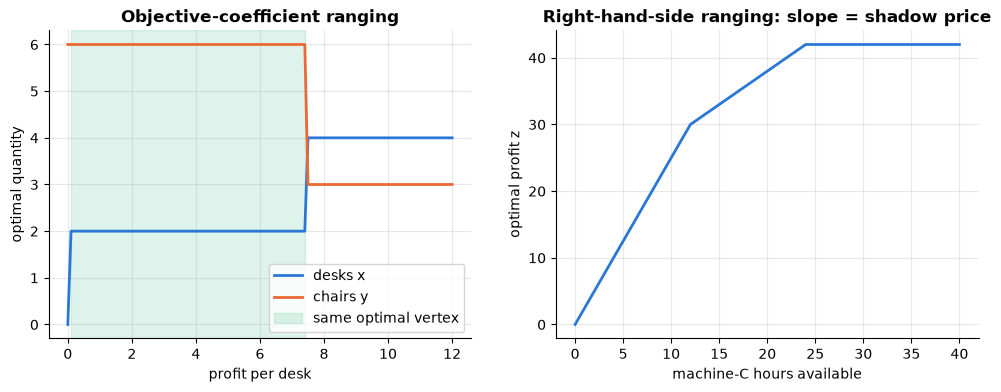

In [20]:
profits = np.linspace(0, 12, 121)
sol = []
for p in profits:
    r = simplex([p, 5], workshop_cons)
    sol.append({"desk profit": p, "x": r["x"][0], "y": r["x"][1], "z": r["z"]})
S = pd.DataFrame(sol)
stay = S[(S.x.round(6) == 2) & (S.y.round(6) == 6)]["desk profit"]
print(f"(2, 6) stays optimal for desk profit in [{stay.min():.1f}, {stay.max():.1f}]")

hours_c = np.linspace(0, 40, 161)
zc = [simplex(workshop_c, [workshop_cons[0], workshop_cons[1], ([3, 2], "<=", h)])["z"] for h in hours_c]
slope = np.gradient(zc, hours_c)
in_range = hours_c[np.isclose(slope, 1.0)]
print(f"shadow price of machine C stays 1.0 for hours in about [{in_range.min():.2f}, {in_range.max():.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(S["desk profit"], S.x, label="desks x"); axes[0].plot(S["desk profit"], S.y, label="chairs y")
axes[0].axvspan(stay.min(), stay.max(), color=PALETTE[2], alpha=0.15, label="same optimal vertex")
axes[0].set(xlabel="profit per desk", ylabel="optimal quantity", title="Objective-coefficient ranging"); axes[0].legend()
axes[1].plot(hours_c, zc)
axes[1].set(xlabel="machine-C hours available", ylabel="optimal profit z", title="Right-hand-side ranging: slope = shadow price")
plt.show()

**What just happened?** The plan (2, 6) stays optimal while the desk profit is between **0 and 7.5**; above 7.5 it pays to make more desks and the optimum jumps to the vertex (4, 3). (The grid prints 0.1 and 7.4 because at exactly 0 and 7.5 there are ties: a whole edge is optimal and the solver may return the other end.) The optimal profit is a piecewise-linear, concave function of machine-C hours: slope 2.5 up to 12 hours, then the shadow price **1.0** from **12 to 24 hours** (the numerical slope blurs each kink by one grid step, hence 12.25 and 23.75), then 0 once machine C is no longer the bottleneck. Outside that range another constraint becomes binding and the slope changes.

### 7.2 Infeasibility: which constraints conflict?
A real model has hundreds of constraints; "infeasible" alone is not helpful. An **irreducible infeasible subset (IIS)** is a set of constraints that is infeasible but becomes feasible if *any one* of them is removed. The **deletion filter** finds one: try dropping each constraint; if the rest is still infeasible, drop it for good.

Example: a call centre needs staff across 3 shifts (variables $s_1, s_2, s_3$).

In [21]:
staff_cons = {
    "morning >= 8":            ([1, 0, 0], ">=", 8),
    "afternoon >= 10":         ([0, 1, 0], ">=", 10),
    "night >= 4":              ([0, 0, 1], ">=", 4),
    "afternoon <= morning+1":  ([-1, 1, 0], "<=", 1),
    "night <= 6":              ([0, 0, 1], "<=", 6),
    "budget: 50*total <= 1000": ([50, 50, 50], "<=", 1000),
    "total >= 18":             ([1, 1, 1], ">=", 18),
}
print("full model:", simplex([1, 1, 1], list(staff_cons.values()), maximize=False)["status"])


def deletion_filter(cons_dict):
    keep = dict(cons_dict)
    for name in list(cons_dict):
        trial = {k: v for k, v in keep.items() if k != name}
        if simplex([0] * 3, list(trial.values()))["status"] == "infeasible":
            keep = trial                         # still infeasible without it -> not needed in the IIS
    return keep


iis = deletion_filter(staff_cons)
print("irreducible infeasible subset:", list(iis))
for name in iis:                                 # check irreducibility: removing any one makes it feasible
    rest = [v for k, v in iis.items() if k != name]
    assert simplex([0] * 3, rest)["status"] == "optimal"
print("removing any one of them makes the subset feasible -> irreducible")

full model: infeasible
irreducible infeasible subset: ['afternoon >= 10', 'night >= 4', 'afternoon <= morning+1', 'budget: 50*total <= 1000']
removing any one of them makes the subset feasible -> irreducible


**What just happened?** The deletion filter kept four constraints: afternoon $\ge 10$ together with "afternoon $\le$ morning + 1" forces morning $\ge 9$, so with night $\ge 4$ we need at least $9 + 10 + 4 = 23$ staff, but the budget allows only $1000 / 50 = 20$. Removing any one of the four fixes it. An IIS is **not unique**: {morning $\ge 8$, afternoon $\ge 10$, night $\ge 4$, budget} ($22 > 20$) is another one; which one you get depends on the order the filter tries constraints. Commercial solvers (Gurobi, CPLEX) have built-in IIS finders based on the same idea; HiGHS reports only the status.

| symptom | likely cause | what to do |
|---|---|---|
| infeasible | conflicting requirements, a sign error, wrong units | find an IIS; check $\ge$/$\le$ directions |
| unbounded | a missing constraint (e.g. forgot a capacity) | look at which variable grows; add the limit |
| "optimal" but nonsense | wrong objective sign (max vs min), units | sanity-check with a hand-made feasible point |

---
## 8. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same tool fits outlier-proof regression, sparse classifiers, GPU schedules and ad budgets.

### 8.1 L1 (least-absolute-deviation) regression is an LP
Least squares minimises $\sum r_i^2$ and is pulled hard by outliers. **Least absolute deviations (LAD)** minimises $\sum |r_i|$ with $r_i = y_i - w x_i - b$. With the absolute-value trick ($t_i \ge r_i$, $t_i \ge -r_i$) it becomes an LP. It is the median regression, i.e. `sklearn.linear_model.QuantileRegressor(quantile=0.5, alpha=0)`, which itself calls HiGHS.

true line      : y = 2.000 x + 1.000
LAD via our LP : y = 1.975 x + 1.306
QuantileRegr.  : y = 1.975 x + 1.306
least squares  : y = 2.019 x + 4.630


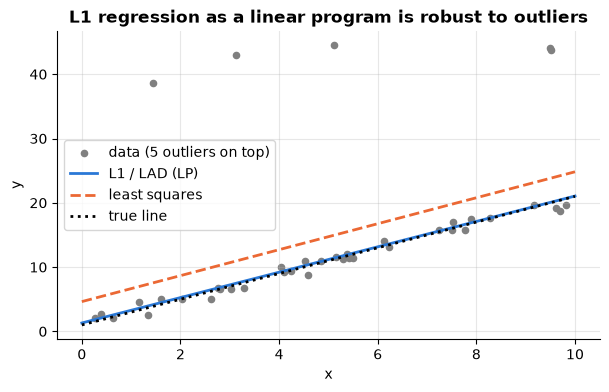

In [22]:
from sklearn.linear_model import QuantileRegressor

rng = np.random.default_rng(1)
n = 40
xr = rng.uniform(0, 10, n)
yr = 2.0 * xr + 1.0 + rng.normal(0, 1, n)
yr[:5] += rng.uniform(20, 40, 5)                    # five big outliers
# variables: w, b (free -> split into +/- parts), t_1..t_n >= 0
# columns: w+, w-, b+, b-, t_1..t_n
c_lad = np.concatenate([[0, 0, 0, 0], np.ones(n)])
A_ub = np.zeros((2 * n, 4 + n)); b_ub = np.zeros(2 * n)
for i in range(n):
    #  y_i - (w x_i + b) <= t_i   ->  -x_i w - b - t_i <= -y_i
    A_ub[2 * i, :4] = [-xr[i], xr[i], -1, 1]; A_ub[2 * i, 4 + i] = -1; b_ub[2 * i] = -yr[i]
    #  (w x_i + b) - y_i <= t_i
    A_ub[2 * i + 1, :4] = [xr[i], -xr[i], 1, -1]; A_ub[2 * i + 1, 4 + i] = -1; b_ub[2 * i + 1] = yr[i]
r = linprog(c_lad, A_ub=A_ub, b_ub=b_ub, bounds=[(0, None)] * (4 + n), method="highs")
w_lad, b_lad = r.x[0] - r.x[1], r.x[2] - r.x[3]
w_ls, b_ls = np.polyfit(xr, yr, 1)
qr = QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs").fit(xr[:, None], yr)
print(f"true line      : y = 2.000 x + 1.000")
print(f"LAD via our LP : y = {w_lad:.3f} x + {b_lad:.3f}")
print(f"QuantileRegr.  : y = {qr.coef_[0]:.3f} x + {qr.intercept_:.3f}")
print(f"least squares  : y = {w_ls:.3f} x + {b_ls:.3f}")
assert abs(w_lad - qr.coef_[0]) < 1e-4 and abs(b_lad - qr.intercept_) < 1e-4

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(xr, yr, s=20, color="grey", label="data (5 outliers on top)")
xx = np.linspace(0, 10, 2)
ax.plot(xx, w_lad * xx + b_lad, label="L1 / LAD (LP)")
ax.plot(xx, w_ls * xx + b_ls, "--", label="least squares")
ax.plot(xx, 2 * xx + 1, ":", color="black", label="true line")
ax.set(xlabel="x", ylabel="y", title="L1 regression as a linear program is robust to outliers"); ax.legend(); plt.show()

**What just happened?** Our LP and scikit-learn's `QuantileRegressor` found the same line, close to the true slope 2, while least squares is dragged up by the five outliers.

### 8.2 The L1-norm SVM is an LP and selects features
The usual SVM is a quadratic program (it penalises $\|w\|_2^2$; see [`05_svm`](../../03_Machine_Learning/01_supervised/05_svm.ipynb)). Replacing it with $\|w\|_1$ gives an LP that also produces **sparse** weights, i.e. built-in feature selection (Bradley & Mangasarian, 1998):
$$\min_{w,b,\xi}\; \|w\|_1 + C\sum_i \xi_i \quad\text{s.t.}\quad y_i(w^\top x_i + b) \ge 1 - \xi_i,\; \xi_i \ge 0.$$

In [23]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

Xs, ys = make_classification(n_samples=300, n_features=20, n_informative=3, n_redundant=0, n_repeated=0,
                             n_clusters_per_class=1, class_sep=1.5, shuffle=False, random_state=0)
ys = 2 * ys - 1                                       # labels in {-1, +1}
Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.3, random_state=0)
nS, d = Xtr.shape
def l1_svm(Cpen):
    # columns: w+ (d), w- (d), b+, b-, xi (nS)  -- all >= 0
    c_svm = np.concatenate([np.ones(2 * d), [0, 0], Cpen * np.ones(nS)])
    # y_i (w.x_i + b) >= 1 - xi_i   ->   -y_i x_i.w+ + y_i x_i.w- - y_i b+ + y_i b- - xi_i <= -1
    A = np.hstack([-ytr[:, None] * Xtr, ytr[:, None] * Xtr, -ytr[:, None], ytr[:, None], -np.eye(nS)])
    r = linprog(c_svm, A_ub=A, b_ub=-np.ones(nS), bounds=[(0, None)] * len(c_svm), method="highs")
    return r.x[:d] - r.x[d:2 * d], r.x[2 * d] - r.x[2 * d + 1]


rows = []
for Cpen in [0.01, 0.05, 0.1, 0.3, 1.0]:
    w, b0 = l1_svm(Cpen)
    rows.append({"C": Cpen, "test accuracy": np.mean(np.sign(Xte @ w + b0) == yte),
                 "non-zero weights": int((np.abs(w) > 1e-6).sum()), "which": np.flatnonzero(np.abs(w) > 1e-6).tolist()})
print(pd.DataFrame(rows).to_string(index=False))
print("(the informative features are 0, 1, 2)")

   C  test accuracy  non-zero weights                                                       which
0.01         0.9667                 1                                                         [0]
0.05         0.9778                 3                                                   [0, 1, 2]
0.10         0.9778                 4                                               [0, 1, 2, 17]
0.30         0.9889                12                 [0, 1, 2, 5, 7, 11, 13, 14, 15, 16, 17, 19]
1.00         0.9889                17 [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18]
(the informative features are 0, 1, 2)


**What just happened?** With `shuffle=False`, features 0–2 carry the signal and 3–19 are pure noise. A small $C$ (strong L1 penalty) gives exactly zero weight to most features: at $C = 0.05$ the LP keeps **exactly the three informative features** with 97.8% test accuracy. Larger $C$ trusts the training data more, lets noise features in (17 non-zero weights at $C = 1$) and gains only about one point of accuracy. That is the same sparsity effect as Lasso, obtained here from a linear program; $C$ is chosen by cross-validation in practice.

### 8.3 Ad-budget allocation and the value of one more dollar
A marketing team splits a 100k budget across four channels. Each channel has an expected conversions-per-thousand rate, a maximum useful spend, and policy requires at least 10k on brand search. The **shadow price of the budget constraint** tells the CFO how many extra conversions one more thousand would buy.

In [24]:
channels = ["search", "social", "video", "email"]
rate = np.array([12.0, 9.0, 7.0, 15.0])         # conversions per 1k spent
cap_k = np.array([40.0, 50.0, 60.0, 10.0])      # spend beyond this is wasted (saturation)
res = linprog(-rate, A_ub=[np.ones(4)], b_ub=[100], bounds=[(10, cap_k[0])] + [(0, cap_k[i]) for i in range(1, 4)], method="highs")
print(pd.DataFrame({"channel": channels, "spend (k)": np.abs(res.x.round(1)), "cap (k)": cap_k, "rate": rate}).to_string(index=False))
print(f"expected conversions = {-res.fun:.0f}; shadow price of budget = {-res.ineqlin.marginals[0]:.1f} conversions per extra 1k")

channel  spend (k)  cap (k)  rate
 search       40.0     40.0  12.0
 social       50.0     50.0   9.0
  video        0.0     60.0   7.0
  email       10.0     10.0  15.0
expected conversions = 1080; shadow price of budget = 7.0 conversions per extra 1k


**What just happened?** The LP fills channels in order of conversion rate until each saturates: email (10k), search (40k) and social (50k) are all at their caps, which uses the whole 100k, and video gets nothing. One more thousand would therefore go to video, so the budget's shadow price is **7 conversions per 1k**, video's rate (not the average rate of 10.8). Marginal value, not average value, is what a budget decision needs. Real systems use the same LP-duality idea at scale: in online ad allocation, the dual prices act as "bid multipliers" that let each ad server decide locally.

### 8.4 Where else LP/MILP shows up in AI

| AI problem | optimisation model |
|---|---|
| **MAP inference** in graphical models | LP relaxation of an ILP over discrete labels |
| **Optimal transport** / Wasserstein distance (domain adaptation, generative models) | a transportation LP (Section 1); Sinkhorn solves an entropy-regularised version |
| **Verifying ReLU networks** (is there an adversarial input within $\epsilon$?) | MILP with a binary per ReLU and big-M constraints (Tjeng et al., 2019) |
| **Scheduling** GPU jobs, LLM batch serving, cluster capacity planning | MILP, min-max makespan (Section 6) |
| **Learning to branch** | graph neural networks that imitate strong branching inside B&B (Gasse et al., 2019) |
| **Sparse models**: L1 regression, L1-SVM, compressed sensing (basis pursuit) | LP |
| **Constraint solving inside LLM agents** | the LLM writes a model, a solver (HiGHS, OR-Tools) solves it exactly |

Related notebooks: [optimization](../../14_Mathematics/06_optimization.ipynb) (continuous optimisation), [SVM](../../03_Machine_Learning/01_supervised/05_svm.ipynb), [NP-completeness](02_np_completeness_and_reductions.ipynb), [approximation algorithms](03_approximation_and_parameterized_algorithms.ipynb) (LP rounding), [network flows](04_network_flows_and_matching.ipynb) (flow problems are LPs with integral optima), [constraint satisfaction](../classical_ai/06_constraint_satisfaction.ipynb), and [ML system design](../../22_ML_System_Design/01_hld_ml_systems.ipynb).

### 8.5 Optional: the same model in a modelling library
Writing matrices by hand is error-prone. Modelling libraries such as **PuLP** or Google **OR-Tools** let you write constraints with named variables. They are optional here; the cell skips cleanly if neither is installed.

In [25]:
try:
    import pulp
    prob = pulp.LpProblem("workshop", pulp.LpMaximize)
    x = pulp.LpVariable("desks", lowBound=0); y = pulp.LpVariable("chairs", lowBound=0)
    prob += 3 * x + 5 * y
    prob += x <= 4; prob += 2 * y <= 12; prob += 3 * x + 2 * y <= 18
    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    print("PuLP:", pulp.value(prob.objective), x.value(), y.value())
except ImportError:
    print("PuLP not installed: skipping (optional). `pip install pulp` to try it.")
try:
    from ortools.linear_solver import pywraplp
    s = pywraplp.Solver.CreateSolver("GLOP")
    x, y = s.NumVar(0, s.infinity(), "x"), s.NumVar(0, s.infinity(), "y")
    s.Add(x <= 4); s.Add(2 * y <= 12); s.Add(3 * x + 2 * y <= 18)
    s.Maximize(3 * x + 5 * y); s.Solve()
    print("OR-Tools:", s.Objective().Value(), x.solution_value(), y.solution_value())
except ImportError:
    print("OR-Tools not installed: skipping (optional). `pip install ortools` to try it.")

PuLP not installed: skipping (optional). `pip install pulp` to try it.
OR-Tools not installed: skipping (optional). `pip install ortools` to try it.


---
## 9. Summary tables

> 💬 **In plain English:** the whole notebook in two tables.

| problem class | variables | complexity | exact methods | typical size solved |
|---|---|---|---|---|
| LP | continuous | **P** | simplex, interior point | millions of variables |
| ILP / MILP | some integer | **NP-hard** | branch-and-bound / branch-and-cut | thousands of binaries (instance-dependent) |
| totally unimodular LP (transport, assignment, flow) | integer for free | P | simplex, network algorithms | very large |

| concept | one-line meaning |
|---|---|
| vertex / basic feasible solution | corner of the feasible region; LP optima are found here |
| reduced cost | change in objective per unit increase of a non-basic variable |
| ratio test | how far you can move before a basic variable hits 0 |
| degeneracy | a basic variable is 0; pivots may not move (cycling risk) |
| dual / shadow price | value of one more unit of a resource |
| LP relaxation | drop integrality; gives a bound for the ILP |
| integrality gap | distance between LP-relaxation bound and integer optimum |
| big-M | a binary switches a constraint on/off; keep $M$ small |
| IIS | minimal set of conflicting constraints |

In [26]:
summary = pd.DataFrame(sorted(CHECKS.items()), columns=["check", "random cases passed"])
print(summary.to_string(index=False))
print("\nevery assert passed")

                     check  random cases passed
B&B knapsack vs DP vs milp                   40
          simplex vs HiGHS                  600
            strong duality                  300
              weak duality                 1969

every assert passed


---
## 10. Recap

> 💬 **In plain English:** the key ideas in a few bullets, then practice.

- An **LP** = decision variables + linear objective + linear constraints. Formulate first, solve second.
- The feasible region is a convex polytope; if an optimum exists, one is at a **vertex**.
- The **simplex method** walks from vertex to better vertex; **Bland's rule** prevents cycling; worst case is exponential (**Klee–Minty**), but LP itself is in **P** (ellipsoid, interior point).
- Every LP has a **dual**; at the optimum the values are equal (strong duality), and the dual variables are **shadow prices**.
- **Integer** programs are NP-hard. Rounding the LP fails; **branch-and-bound** uses LP bounds to prune; tight formulations shrink the tree.
- Modelling tricks (big-M, indicators, absolute values, min-max) make many "non-linear" requirements linear.
- Always check: sensitivity ranges for robustness, an **IIS** for infeasibility, and a second solver or brute force for correctness.
- AI uses: L1 regression, L1-SVM, optimal transport, MAP inference, network verification, scheduling and budget allocation.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested (against `linprog`, `milp` or a DP) when this notebook was built.

**1. (Easy, conceptual)** Convert to canonical form ($\max$, $\le$, $x \ge 0$): $\min\; 2x_1 - x_2$ s.t. $x_1 + x_2 \ge 3$, $x_1 - x_2 = 1$, $x_1 \ge 0$, $x_2$ free.

<details><summary>Show solution</summary>

Negate the objective: $\max -2x_1 + x_2$. Replace the free $x_2$ by $x_2^+ - x_2^-$ with both $\ge 0$. Multiply the $\ge$ row by $-1$: $-x_1 - x_2^+ + x_2^- \le -3$. Write the equality as two inequalities: $x_1 - x_2^+ + x_2^- \le 1$ and $-x_1 + x_2^+ - x_2^- \le -1$. All variables $x_1, x_2^+, x_2^- \ge 0$.

</details>

**2. (Easy, conceptual)** Write the dual of $\max\; 4x_1 + 3x_2$ s.t. $x_1 + x_2 \le 10$, $2x_1 + x_2 \le 16$, $x \ge 0$. Without solving, why must the dual optimum be at least $4 \cdot 6 + 3 \cdot 4 = 36$?

<details><summary>Show solution</summary>

Dual: $\min\; 10y_1 + 16y_2$ s.t. $y_1 + 2y_2 \ge 4$, $y_1 + y_2 \ge 3$, $y \ge 0$. The point $x = (6, 4)$ is primal feasible ($6 + 4 = 10$, $12 + 4 = 16$) with value 36, and by **weak duality** every dual-feasible $y$ has $b^\top y \ge 36$. (In fact both optima equal 36 at $x = (6,4)$, $y = (2, 1)$.)

</details>

**3. (Easy, coding)** Solve with `linprog`: $\max 5a + 4b$ s.t. $6a + 4b \le 24$, $a + 2b \le 6$, $-a + b \le 1$, $b \le 2$, $a, b \ge 0$.

<details><summary>Show solution</summary>

```python
from scipy.optimize import linprog
# max 5a + 4b  s.t.  6a + 4b <= 24,  a + 2b <= 6,  -a + b <= 1,  b <= 2
res = linprog([-5, -4], A_ub=[[6, 4], [1, 2], [-1, 1], [0, 1]], b_ub=[24, 6, 1, 2], method="highs")
print(-res.fun, res.x)            # 21.0 at a=3, b=1.5
```

</details>

**4. (Medium, coding)** Write `best_vertex(c, A, b)` that solves a 2-variable LP $\max\{c^\top x : Ax \le b, x \ge 0\}$ by enumerating vertices, and test it against `linprog` on 200 random bounded LPs.

<details><summary>Show solution</summary>

```python
import itertools
def best_vertex(c, A, b):
    """Max c.x over {Ax <= b, x >= 0} in 2-D by enumerating constraint-line intersections."""
    import numpy as np
    A = np.asarray(A, float); b = np.asarray(b, float)
    lines = list(zip(A, b)) + [(np.array([1.0, 0]), 0.0), (np.array([0, 1.0]), 0.0)]
    best = None
    for (a1, b1), (a2, b2) in itertools.combinations(lines, 2):
        M = np.vstack([a1, a2])
        if abs(np.linalg.det(M)) < 1e-12:
            continue
        p = np.linalg.solve(M, [b1, b2])
        if (A @ p <= b + 1e-9).all() and (p >= -1e-9).all():
            val = float(np.dot(c, p))
            if best is None or val > best[0]:
                best = (val, p)
    return best
```
Tested on 200 random instances with positive $A$ and $b$ (so the region is bounded and contains the origin): same optimum as `linprog`.

</details>

**5. (Medium, modelling)** Three candidate ambulance stations cost 4, 3 and 5. Station 1 covers districts {1, 2, 5}, station 2 covers {2, 3, 4}, station 3 covers {1, 4, 5}. Choose stations so every district is covered at minimum cost. Formulate as an ILP and solve with `milp`. (This is **set cover**, NP-hard in general.)

<details><summary>Show solution</summary>

Binary $o_k$ = open station $k$. Minimise $4o_1 + 3o_2 + 5o_3$ s.t. for each district, the sum of $o_k$ over stations covering it is $\ge 1$.
```python
from scipy.optimize import milp, LinearConstraint, Bounds
import numpy as np
# Variables: open_1..open_3 (binary). Cover every district by at least one open station.
covers = np.array([[1, 1, 0, 0, 1],      # station 1 covers districts 1, 2, 5
                   [0, 1, 1, 1, 0],      # station 2 covers 2, 3, 4
                   [1, 0, 0, 1, 1]])     # station 3 covers 1, 4, 5
cost = np.array([4, 3, 5])
res = milp(cost, constraints=LinearConstraint(covers.T, 1, np.inf), integrality=np.ones(3), bounds=Bounds(0, 1))
print(res.fun, res.x)                   # 7: open stations 1 and 2
```
Answer: open stations 1 and 2, cost 7.

</details>

**6. (Hard, coding)** Implement branch-and-bound for 0/1 knapsack **without any LP solver**, using the fact that the LP relaxation of knapsack is solved by the greedy fractional algorithm (sort by value/weight, take a fraction of the first item that does not fit). Test it against the DP on 300 random instances.

<details><summary>Show solution</summary>

```python
import math
def bb_knapsack(values, weights, W):
    """Branch-and-bound for 0/1 knapsack with the fractional (greedy LP) bound."""
    items = sorted(zip(values, weights), key=lambda t: t[0] / t[1], reverse=True)
    best = 0
    def bound(i, cap, val):                     # LP relaxation of the remaining items = fractional greedy
        for v, w in items[i:]:
            if w <= cap:
                cap -= w; val += v
            else:
                return val + v * cap / w
        return val
    def go(i, cap, val):
        nonlocal best
        best = max(best, val)
        if i == len(items) or bound(i, cap, val) <= best:
            return                              # prune
        v, w = items[i]
        if w <= cap:
            go(i + 1, cap - w, val + v)         # take item i
        go(i + 1, cap, val)                     # skip item i
    go(0, W, 0)
    return best
```
The fractional greedy value is exactly the LP-relaxation optimum of the remaining subproblem, so it is a valid upper bound for pruning.

</details>

**7. (Hard, conceptual)** Why does the simplex method on the transportation problem with integer supplies and demands always return an integer solution, while the same method on the knapsack LP can return a fractional one?

<details><summary>Show solution</summary>

The transportation constraint matrix is **totally unimodular** (every square submatrix has determinant $-1$, $0$ or $1$; it is the incidence matrix of a bipartite graph). By Cramer's rule every basic solution $B^{-1}b$ is then integral when $b$ is integral, so every vertex is integral. The knapsack row has arbitrary weights such as 7 and 4, so $B^{-1}b$ contains fractions like $13/7$.

</details>

**8. (Hard, conceptual)** Show that if $x^*$ and $y^*$ are primal- and dual-feasible and $c^\top x^* = b^\top y^*$, then both are optimal.

<details><summary>Show solution</summary>

By weak duality every primal-feasible $x$ satisfies $c^\top x \le b^\top y^*= c^\top x^*$, so $x^*$ is optimal for the max problem. Symmetrically, every dual-feasible $y$ satisfies $b^\top y \ge c^\top x^* = b^\top y^*$, so $y^*$ is optimal for the min problem. Equal objective values are therefore a **certificate of optimality**, which is how solvers prove they are done.

</details>

## Further reading (additional learning resources)
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022), ch. 29 "Linear Programming" (formulation, simplex, duality) and §35.4 (LP rounding for weighted vertex cover).
- Bertsimas & Tsitsiklis, *Introduction to Linear Optimization* (Athena Scientific, 1997): ch. 2–5 (geometry, simplex, duality, sensitivity).
- Chvátal, *Linear Programming* (Freeman, 1983): the cycling example and Bland's rule.
- Wolsey, *Integer Programming* (2nd ed., Wiley, 2020): branch-and-bound, formulations, cutting planes.
- Boyd & Vandenberghe, *Convex Optimization* (free PDF at https://web.stanford.edu/~boyd/cvxbook/), §4.3 (LP) and ch. 5 (duality).
- SciPy documentation for [`linprog`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html) and [`milp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html); HiGHS: https://highs.dev
- GeeksforGeeks: [Linear Programming](https://www.geeksforgeeks.org/linear-programming/).

## Next notebook
➡️ [06 · Streaming and sketching algorithms](06_streaming_and_sketching_algorithms.ipynb): counting, sampling and deduplicating data that is too big to store, with tiny memory and provable error bounds.